# Proyecto Bimestral — Clustering No Supervisado con DBSCAN y Clustering Jerárquico Aglomerativo
## Segmentación de pacientes pediátricos con sospecha de apendicitis

**Materia:** Sistemas Inteligentes | **Dataset:** `app_mod.xlsx` (hoja `Todo`)
**Condiciones del grupo (`condiciones.txt`):** *"todos, usar PCA y UMAP para clusterizar"* →
1. Usar la hoja **`Todo`** (niñas y niños juntos) con **todas** las variables clínicas.
2. Aplicar **PCA** y **UMAP** como métodos de reducción de dimensionalidad y **clusterizar en ambos espacios**.

---

### ¿De qué trata este proyecto?

Cuando un niño llega a urgencias con dolor abdominal, el médico debe decidir rápido si es apendicitis o
una dolencia menor. En niños es difícil: no siempre saben describir el dolor y los síntomas se parecen a los
de otras enfermedades.

Exploramos si **DBSCAN** y el **Clustering Jerárquico Aglomerativo (Ward)** son capaces de agrupar a los
pacientes por la similitud de sus síntomas, análisis de sangre y ecografía, **sin conocer el diagnóstico**.

### Diseño experimental

| | Espacio PCA | Espacio UMAP |
|---|---|---|
| **DBSCAN** | Experimento 1 (Punto 3.1) | Experimento 2 (Punto 3.2) |
| **Aglomerativo (Ward)** | Experimento 3 (Punto 4.1) | Experimento 4 (Punto 4.2) |

El diagnóstico real solo se usa **al final** de cada experimento para validar si los grupos tienen sentido clínico.

In [1]:
# Librerías
import warnings
warnings.filterwarnings('ignore')
import os, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import umap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage, set_link_color_palette

# Estilo visual común para todas las gráficas
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10.5, 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25})
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']  # orden fijo por cluster
COLOR_RUIDO = '#9a9a9a'
set_link_color_palette(COLORES)
SEMILLA = 42

# Versiones (UMAP puede dar resultados distintos entre versiones; ver Punto 2.4)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | umap-learn {umap.__version__}")

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | umap-learn 0.6.0


---
## Punto 1 — Explicación de la base, las variables y EDA (1 pt)

`app_mod.xlsx` contiene datos de **pacientes pediátricos** atendidos en urgencias por dolor abdominal
(versión modificada del *Regensburg Pediatric Appendicitis Dataset*). Tiene 4 hojas: `Todo`, `niñas`, `niños`
y `Data Summary` (diccionario de variables). Por la condición del grupo trabajamos con la hoja **`Todo`**.

| Variable | Tipo | Descripción |
|---|---|---|
| `Age` | Numérica (años) | Edad del paciente |
| `BMI` | Numérica (kg/m²) | Índice de masa corporal. Un BMI alto dificulta palpar el abdomen y ver el apéndice. |
| `Sex` | Binaria | Sexo (`female` / `male`) |
| `Diagnosis` | Binaria | Diagnóstico final (`appendicitis` / `no appendicitis`). **No se usa para clusterizar.** |
| `Alvarado_Score` | Discreta 0–10 | Score clínico clásico (síntomas + signos + laboratorio). ≥ 7 = alta sospecha. |
| `Paedriatic_Appendicitis_Score` | Discreta 0–10 | Score pediátrico (PAS). ≥ 6 = alta sospecha. |
| `Appendix_Diameter` | Numérica (mm) | Diámetro del apéndice en ecografía. > 6 mm sugiere inflamación. |
| `Migratory_Pain` | Binaria | Dolor que empezó en el ombligo y migró a la fosa ilíaca derecha |
| `Lower_Right_Abd_Pain` | Binaria | Dolor en la fosa ilíaca derecha (FID) |
| `Contralateral_Rebound_Tenderness` | Binaria | Dolor de rebote (irritación peritoneal) |
| `Coughing_Pain` | Binaria | Dolor al toser / saltar |
| `Nausea` | Binaria | Náusea o vómito |
| `Loss_of_Appetite` | Binaria | Pérdida de apetito |
| `Body_Temperature` | Numérica (°C) | Temperatura corporal |
| `WBC_Count` | Numérica (×10³/µL) | Leucocitos (suben con infección) |
| `Neutrophil_Percentage` | Numérica (%) | Porcentaje de neutrófilos |
| `CRP` | Numérica (mg/L) | Proteína C reactiva (marcador de inflamación) |

In [2]:
# Carga de datos
xls = pd.ExcelFile('app_mod.xlsx')
print("Hojas del archivo:", xls.sheet_names)
df_raw = pd.read_excel(xls, sheet_name='Todo')
print(f"Hoja 'Todo': {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas\n")
display(df_raw.head())
print("\nTipos de dato:")
print(df_raw.dtypes.value_counts().to_string())

Hojas del archivo: ['Todo', 'niñas', 'niños', 'Data Summary']
Hoja 'Todo': 782 filas × 17 columnas



,Age,BMI,Sex,Diagnosis,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_Diameter,Migratory_Pain,Lower_Right_Abd_Pain,Contralateral_Rebound_Tenderness,Coughing_Pain,Nausea,Loss_of_Appetite,Body_Temperature,WBC_Count,Neutrophil_Percentage,CRP
0,12.68,16.9,female,appendicitis,4.0,3.0,7.1,no,yes,yes,no,no,yes,37.0,7.7,68.2,0.0
1,14.10,31.9,male,no appendicitis,5.0,4.0,NaN,yes,yes,yes,no,no,yes,36.9,8.1,64.8,3.0
2,14.14,23.3,female,no appendicitis,5.0,3.0,NaN,no,yes,yes,no,no,no,36.6,13.2,74.8,3.0
3,16.37,20.6,female,no appendicitis,7.0,6.0,NaN,yes,yes,no,no,yes,yes,36.0,11.4,63.0,0.0
4,11.08,16.9,female,appendicitis,5.0,6.0,7.0,no,yes,yes,yes,yes,yes,36.9,8.1,44.0,0.0



Tipos de dato:
float64    9
str        8


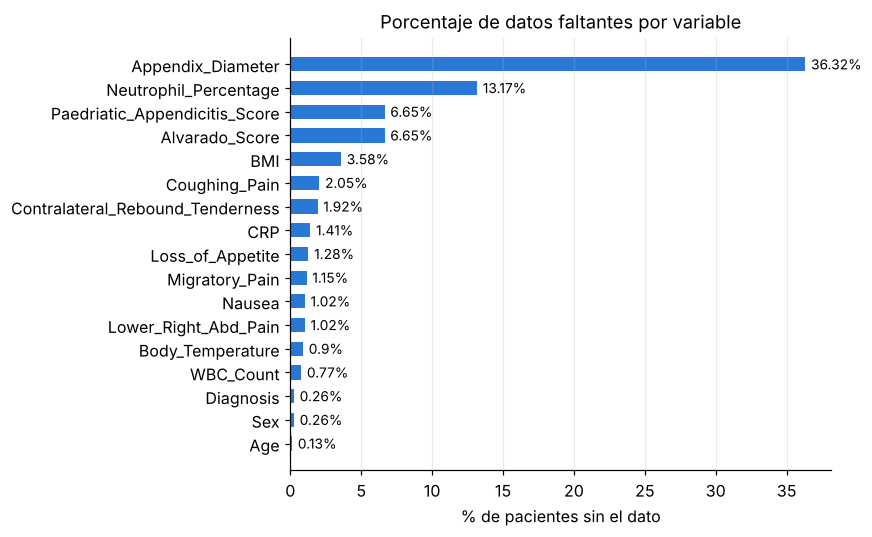

Pacientes según cuántas variables les faltan:
Nº variables faltantes   0    1   2   3   4   5   6   7   8   9   10  11  14  17
Pacientes               420  278  31  18  18   3   3   1   2   2   1   3   1   1

Filas completamente vacías: 1


In [3]:
# 1.1 Datos faltantes
nulos = df_raw.isnull().sum()
tabla_nulos = pd.DataFrame({'Faltantes': nulos, '%': (nulos / len(df_raw) * 100).round(2)})
tabla_nulos = tabla_nulos[tabla_nulos['Faltantes'] > 0].sort_values('%', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabla_nulos.index, tabla_nulos['%'], color=COLORES[0], height=0.6)
for i, v in enumerate(tabla_nulos['%']):
    ax.text(v + 0.4, i, f"{v}%", va='center', fontsize=9)
ax.set_title('Porcentaje de datos faltantes por variable')
ax.set_xlabel('% de pacientes sin el dato')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

nulos_fila = df_raw.isnull().sum(axis=1)
print("Pacientes según cuántas variables les faltan:")
print(nulos_fila.value_counts().sort_index().rename_axis('Nº variables faltantes').to_frame('Pacientes').T.to_string())
print(f"\nFilas completamente vacías: {(nulos_fila == df_raw.shape[1]).sum()}")

**¿Qué observamos en los datos faltantes?**
- Solo **420 de 782 pacientes (54 %)** tienen todas las variables completas.
- `Appendix_Diameter` falta en el **36.3 %**: no siempre se logra visualizar el apéndice en la ecografía.
- `Neutrophil_Percentage` falta en el **13.2 %** y los dos scores (`Alvarado`, `PAS`) en el **6.6 %**.
- Hay **1 fila completamente vacía** y varios registros a los que les faltan más de la mitad de las variables:
  no aportan información real y se eliminan en el Punto 2.

,count,mean,std,min,25%,50%,75%,max
Age,781.0,11.35,3.53,0.00,9.20,11.44,14.10,18.36
BMI,754.0,18.91,4.39,7.83,15.73,18.07,21.19,38.16
Alvarado_Score,730.0,5.92,2.16,0.00,4.00,6.00,8.00,10.00
Paedriatic_Appendicitis_Score,730.0,5.25,1.96,0.00,4.00,5.00,7.00,10.00
Appendix_Diameter,498.0,7.76,2.54,2.70,6.00,7.50,9.10,17.00
Body_Temperature,775.0,37.40,0.90,26.90,36.80,37.20,37.90,40.20
WBC_Count,776.0,12.67,5.37,2.60,8.20,12.00,16.20,37.70
Neutrophil_Percentage,679.0,71.79,14.46,27.20,61.40,75.50,83.60,97.70
CRP,771.0,31.39,57.43,0.00,1.00,7.00,33.00,365.00


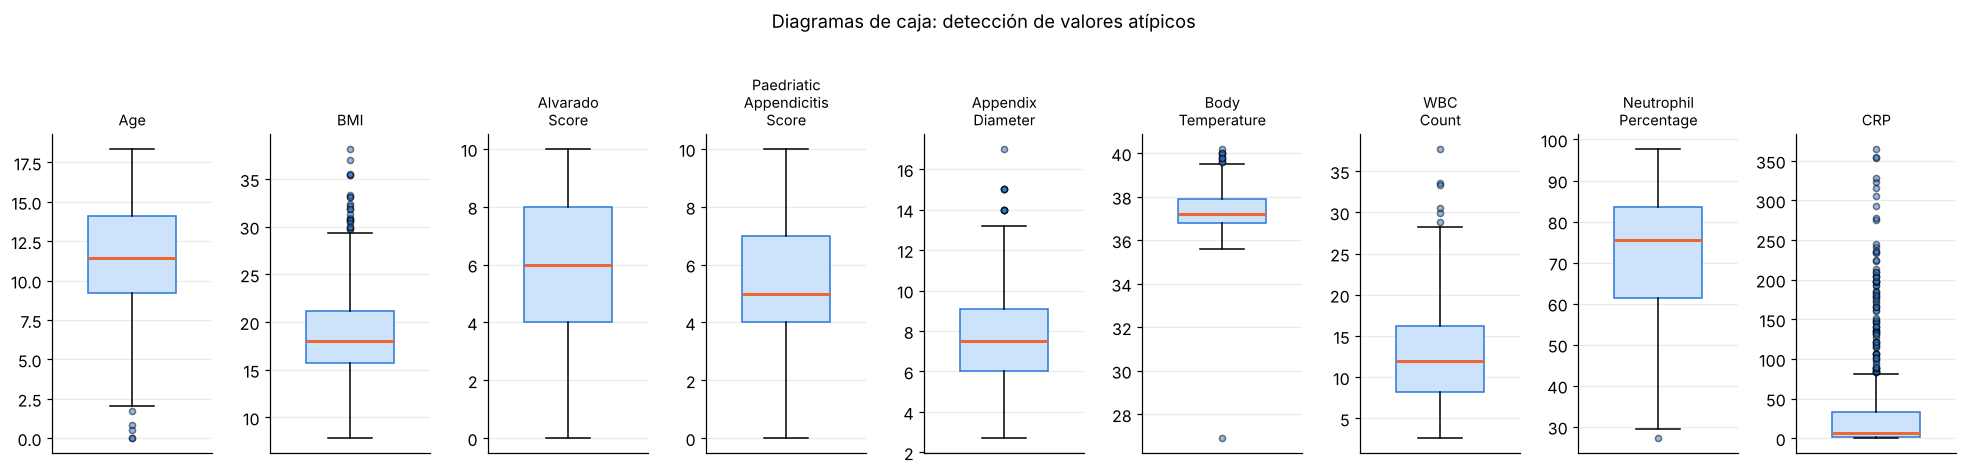

Valores atípicos por regla 1.5·IQR:
          Age  BMI  Alvarado_Score  Paedriatic_Appendicitis_Score  Appendix_Diameter  Body_Temperature  WBC_Count  Neutrophil_Percentage  CRP
Atípicos    5   23               0                              0                 10                12          6                      1   85

Valores fisiológicamente imposibles o sospechosos:
  Edad = 0 años:                 1 paciente(s)
  BMI < 10 kg/m² (adolescentes): 2 paciente(s) -> [[16.0, 7.8], [17.4, 9.0]]
  Temperatura < 30 °C:           1 paciente(s) -> [26.9]


In [4]:
# 1.2 Estadísticas descriptivas y valores atípicos
vars_num = ['Age', 'BMI', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Appendix_Diameter',
            'Body_Temperature', 'WBC_Count', 'Neutrophil_Percentage', 'CRP']
display(df_raw[vars_num].describe().T.round(2))

fig, axes = plt.subplots(1, len(vars_num), figsize=(18, 4.2))
for ax, col in zip(axes, vars_num):
    ax.boxplot(df_raw[col].dropna(), widths=0.55, patch_artist=True,
               boxprops=dict(facecolor='#cde2fb', color=COLORES[0]),
               medianprops=dict(color=COLORES[1], linewidth=2),
               flierprops=dict(marker='o', markersize=4, markerfacecolor=COLORES[0], alpha=0.5))
    ax.set_title(col.replace('_', '\n'), fontsize=9.5)
    ax.set_xticks([])
plt.suptitle('Diagramas de caja: detección de valores atípicos', y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

# Conteo de atípicos con la regla del rango intercuartílico (1.5·IQR)
q1, q3 = df_raw[vars_num].quantile(0.25), df_raw[vars_num].quantile(0.75)
iqr = q3 - q1
atipicos = ((df_raw[vars_num] < q1 - 1.5 * iqr) | (df_raw[vars_num] > q3 + 1.5 * iqr)).sum()
print("Valores atípicos por regla 1.5·IQR:")
print(atipicos.to_frame('Atípicos').T.to_string())

print("\nValores fisiológicamente imposibles o sospechosos:")
print(f"  Edad = 0 años:                 {(df_raw['Age'] == 0).sum()} paciente(s)")
print(f"  BMI < 10 kg/m² (adolescentes): {(df_raw['BMI'] < 10).sum()} paciente(s) -> {df_raw.loc[df_raw['BMI'] < 10, ['Age', 'BMI']].round(1).values.tolist()}")
print(f"  Temperatura < 30 °C:           {(df_raw['Body_Temperature'] < 30).sum()} paciente(s) -> {df_raw.loc[df_raw['Body_Temperature'] < 30, 'Body_Temperature'].tolist()}")

**¿Qué observamos en los valores atípicos?**

Hay que separar dos cosas. Por un lado están los **atípicos reales** y por otro los **errores de registro**:

| Caso | Decisión |
|---|---|
| **PCR**: 85 atípicos por la regla IQR (máximo 365 mg/L) | **Se conservan.** La PCR es muy asimétrica (asimetría ≈ 2.9) y los valores altos aparecen en apendicitis complicada. Son pacientes reales y clínicamente importantes. |
| **Edad**: lactantes de 0.04 a 0.85 años | Se conservan (son raros, pero posibles). |
| **Edad = 0.00** (1 paciente) | Error de registro → `NaN`. |
| **BMI de 7.8 y 9.0** en adolescentes de 16 y 17 años | Incompatible con la vida → `NaN`. |
| **Temperatura de 26.9 °C** | Hipotermia incompatible con un paciente que consulta por dolor abdominal → `NaN`. |

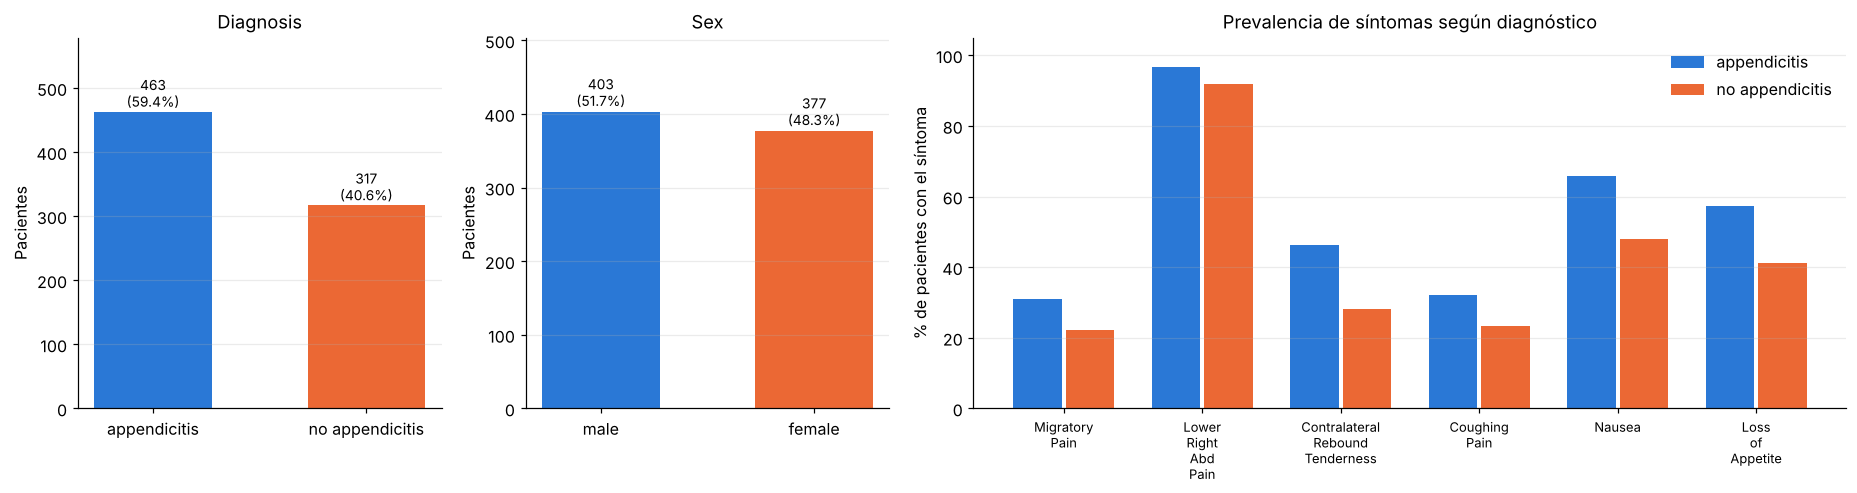

Diagnosis,appendicitis,no appendicitis
Migratory_Pain,30.9,22.2
Lower_Right_Abd_Pain,96.7,91.8
Contralateral_Rebound_Tenderness,46.3,28.2
Coughing_Pain,32.0,23.4
Nausea,65.7,48.1
Loss_of_Appetite,57.5,41.1


In [5]:
# 1.3 Variables categóricas: diagnóstico, sexo y síntomas
sintomas = ['Migratory_Pain', 'Lower_Right_Abd_Pain', 'Contralateral_Rebound_Tenderness',
            'Coughing_Pain', 'Nausea', 'Loss_of_Appetite']

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1, 2.4]})
for ax, col in zip(axes[:2], ['Diagnosis', 'Sex']):
    vc = df_raw[col].value_counts()
    ax.bar(vc.index, vc.values, color=COLORES[:len(vc)], width=0.55)
    for i, v in enumerate(vc.values):
        ax.text(i, v + 8, f"{v}\n({v / vc.sum() * 100:.1f}%)", ha='center', fontsize=9)
    ax.set_title(col); ax.set_ylabel('Pacientes'); ax.set_ylim(0, vc.max() * 1.25)
    ax.grid(axis='x', visible=False)

# % de pacientes con cada síntoma, separados por diagnóstico (solo descriptivo)
pct = (df_raw.groupby('Diagnosis')[sintomas]
       .agg(lambda s: (s == 'yes').sum() / s.notna().sum() * 100).T)
x = np.arange(len(sintomas)); w = 0.38
for j, diag in enumerate(pct.columns):
    axes[2].bar(x + (j - 0.5) * w, pct[diag], width=w - 0.03, color=COLORES[j], label=diag)
axes[2].set_xticks(x)
axes[2].set_xticklabels([s.replace('_', '\n') for s in sintomas], fontsize=8.5)
axes[2].set_ylabel('% de pacientes con el síntoma'); axes[2].set_ylim(0, 105)
axes[2].set_title('Prevalencia de síntomas según diagnóstico')
axes[2].legend(frameon=False); axes[2].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(pct.round(1))

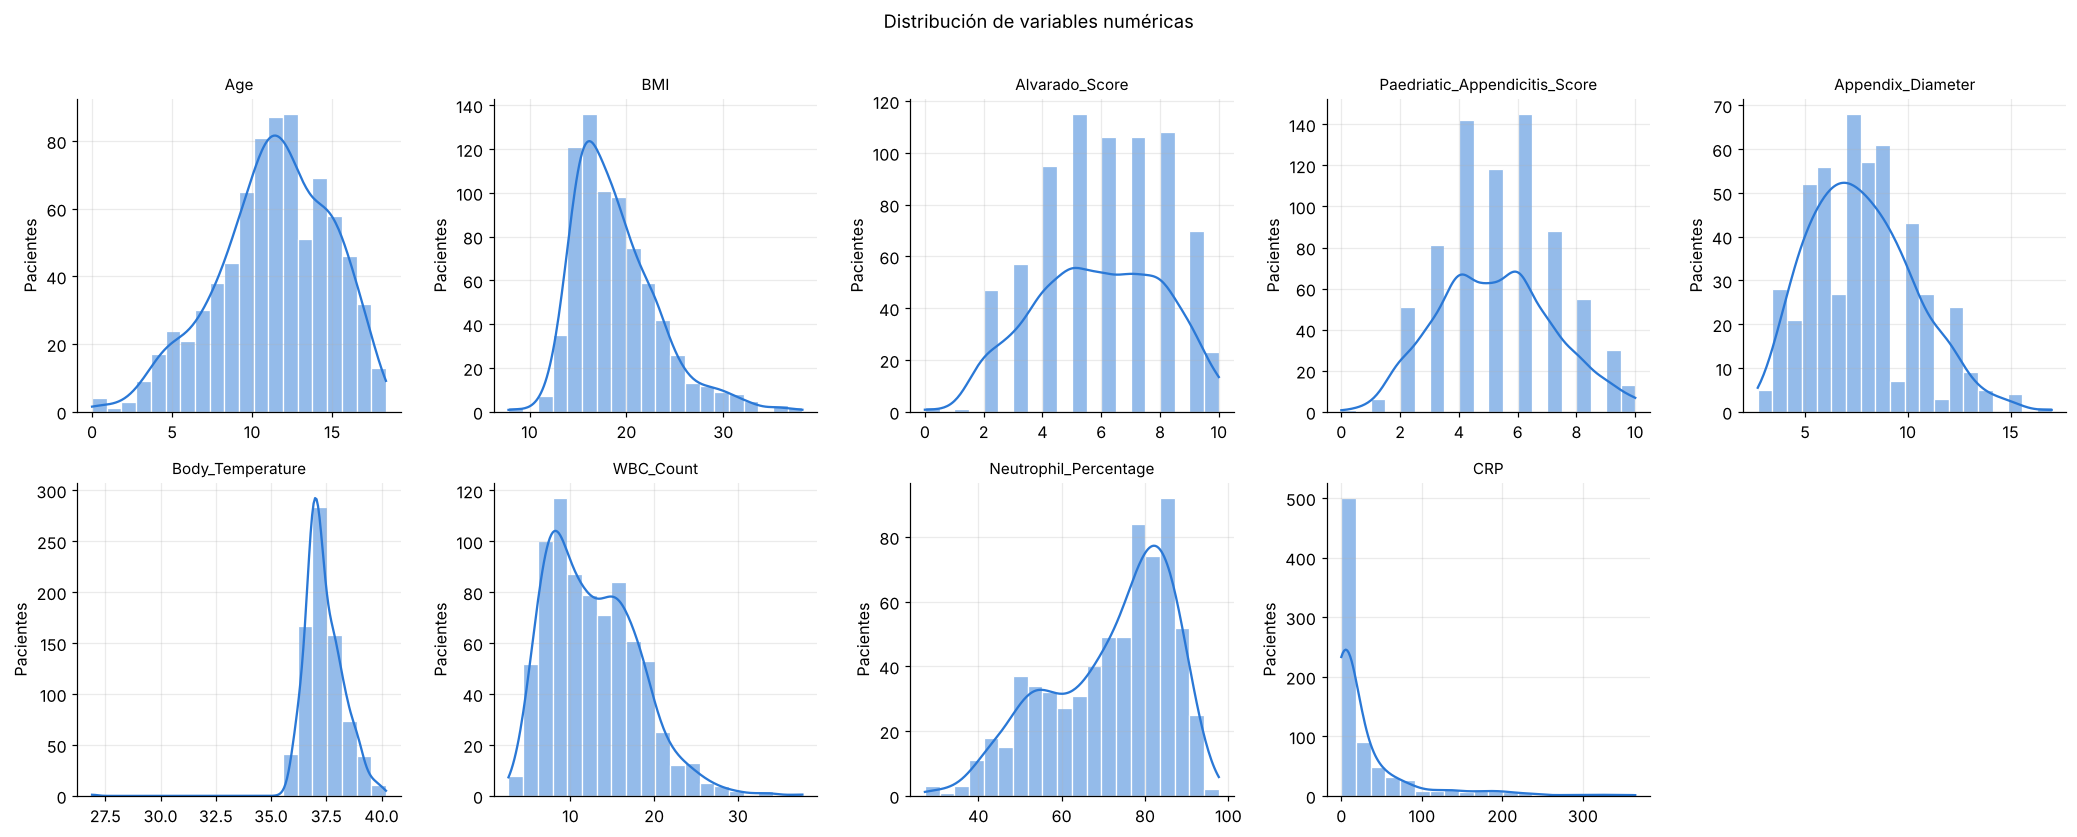

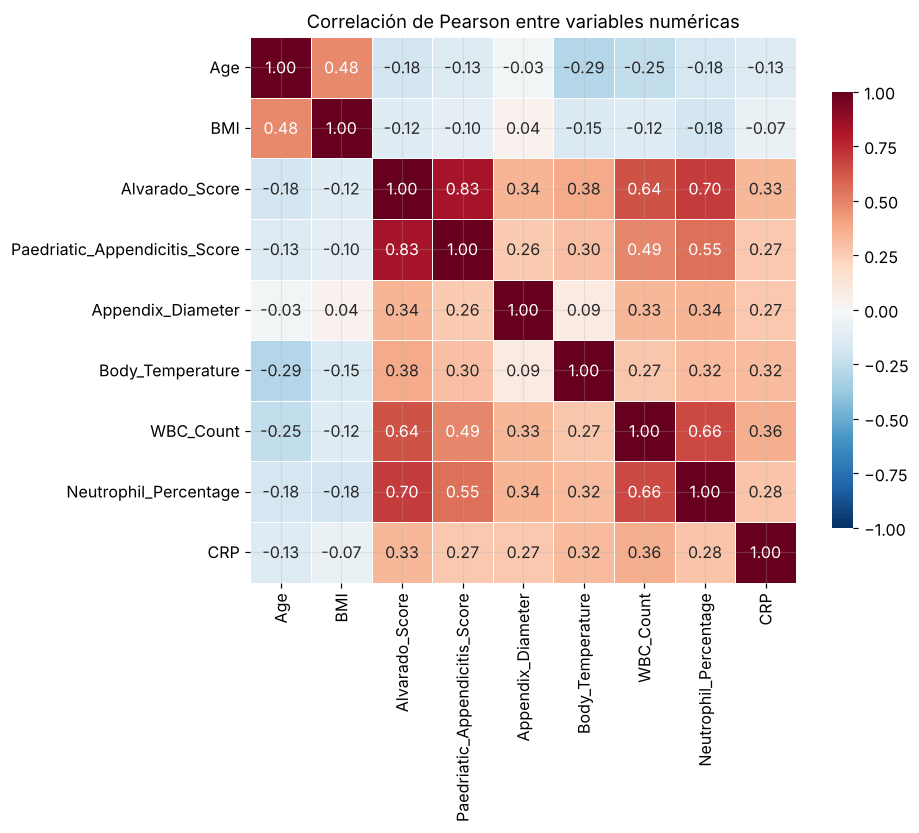

In [6]:
# 1.4 Distribuciones y correlaciones de las variables numéricas
fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
axes = axes.flatten()
for ax, col in zip(axes, vars_num):
    sns.histplot(df_raw[col].dropna(), kde=True, ax=ax, color=COLORES[0], bins=20, edgecolor='white')
    ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('Pacientes')
axes[-1].axis('off')
plt.suptitle('Distribución de variables numéricas', y=1.01, fontsize=12)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7.5))
sns.heatmap(df_raw[vars_num].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlación de Pearson entre variables numéricas')
plt.tight_layout(); plt.show()

**Conclusiones del EDA**
- **Diagnóstico:** 463 apendicitis (59.4 %) frente a 317 no apendicitis (40.6 %). Las clases están razonablemente equilibradas.
- **Sexo:** equilibrado (403 niños y 377 niñas).
- **Síntomas:** el dolor de rebote (46 % frente a 28 %), las náuseas (66 % frente a 48 %) y la pérdida de apetito (58 % frente a 41 %)
  son más frecuentes en apendicitis. El **dolor en la fosa ilíaca derecha (FID)** lo tienen casi todos los pacientes
  (97 % frente a 92 %), así que **casi no distingue** entre diagnósticos. Este detalle será clave para interpretar los clusters.
- **Correlaciones:** `Alvarado` y `PAS` están muy correlacionados (r = 0.83), porque miden lo mismo. Ambos se relacionan con
  los neutrófilos (0.70 / 0.55) y los leucocitos (0.64 / 0.49), ya que los incluyen en su cálculo. La edad se correlaciona con el BMI
  (0.48) y en forma negativa con la temperatura (−0.29). Los niños pequeños suelen presentar cuadros más febriles.
- **Distribuciones:** la PCR (asimetría 2.9), el BMI y los leucocitos tienen colas hacia la derecha. Por eso se imputa con la **mediana**
  y se estandariza antes de calcular distancias.

---
## Punto 2 — Selección de variables y filtros (sin nota)

### 2.1 Decisiones tomadas

| Decisión | Justificación |
|---|---|
| **Hoja `Todo`, sin filtrar por sexo ni edad** | Condición del grupo: *"todos"*. |
| **Usar las 16 variables clínicas** (todas menos `Diagnosis`) | Condición del grupo: *"todos"*. Clustering no supervisado: el algoritmo no debe conocer la respuesta. |
| **`Diagnosis` se guarda aparte** | Solo para la validación externa al final (evitar *data leakage*). |
| **Eliminar registros sin información útil** (> 50 % de variables vacías) | Imputar más de la mitad de un paciente sería inventarlo; esos registros forman grupos artificiales. |
| **Valores imposibles → `NaN`**: edad = 0, BMI < 10, temperatura < 30 °C | Son errores de registro, no pacientes reales. Se imputan después. La PCR alta **se conserva** (es real en apendicitis complicada). |
| **Codificación** `yes/no` → 1/0, `male/female` → 1/0 | Los algoritmos necesitan números para calcular distancias. |
| **Imputación con la mediana** | Robusta frente a asimetrías (PCR, leucocitos). |
| **`StandardScaler`** (media 0, desviación 1) | Las distancias euclidianas no deben depender de las unidades (PCR en cientos vs. síntomas 0/1). |
| **Reducción de dimensionalidad: PCA y UMAP** | Condición del grupo. Se clusteriza en **ambos** espacios y se comparan. |

In [7]:
df = df_raw.copy()

# Filtro 1: eliminar registros con más del 50 % de las variables clínicas vacías
variables_clinicas = [c for c in df.columns if c != 'Diagnosis']
pct_vacio = df[variables_clinicas].isnull().mean(axis=1)
eliminados = df[pct_vacio > 0.5]
df = df[pct_vacio <= 0.5].reset_index(drop=True)
print(f"Registros eliminados por tener > 50 % de datos vacíos: {len(eliminados)}")
print(f"Pacientes que continúan: {len(df)}\n")

# Filtro 2: valores fisiológicamente imposibles -> NaN (se imputarán con la mediana)
reglas = {'Age': df['Age'] <= 0,
          'BMI': df['BMI'] < 10,
          'Body_Temperature': df['Body_Temperature'] < 30}
for col, cond in reglas.items():
    print(f"  {col}: {cond.sum()} valor(es) imposible(s) reemplazado(s) por NaN")
    df.loc[cond, col] = np.nan

# Etiqueta real: se aparta y NO participa en el clustering
y_true = df['Diagnosis'].copy()
X = df.drop(columns=['Diagnosis'])

# Codificación binaria
for s in sintomas:
    X[s] = X[s].map({'yes': 1, 'no': 0})
X['Sex'] = X['Sex'].map({'male': 1, 'female': 0})

# Imputación con mediana + estandarización
X_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X), columns=X.columns)
X_scaled = StandardScaler().fit_transform(X_imp)
print(f"\nMatriz final para clustering: {X_scaled.shape[0]} pacientes × {X_scaled.shape[1]} variables")
print(f"Pacientes sin diagnóstico registrado (solo se excluyen de la validación): {y_true.isna().sum()}")

Registros eliminados por tener > 50 % de datos vacíos: 8
Pacientes que continúan: 774

  Age: 1 valor(es) imposible(s) reemplazado(s) por NaN
  BMI: 2 valor(es) imposible(s) reemplazado(s) por NaN
  Body_Temperature: 1 valor(es) imposible(s) reemplazado(s) por NaN

Matriz final para clustering: 774 pacientes × 16 variables
Pacientes sin diagnóstico registrado (solo se excluyen de la validación): 0


### 2.2 Reducción de dimensionalidad con PCA

**PCA** (Análisis de Componentes Principales) crea nuevas variables (componentes) que son **combinaciones
lineales** de las originales, ordenadas por la cantidad de varianza que explican. Elegimos el número de
componentes que conserva **al menos el 80 % de la varianza** total.

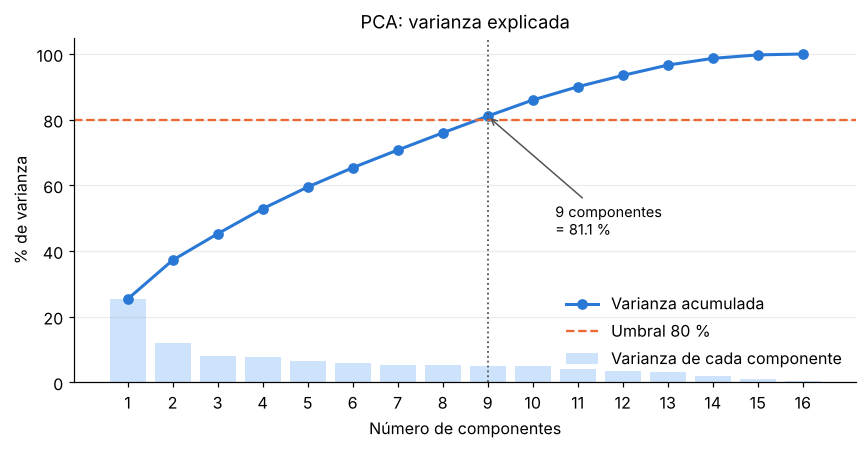

Espacio PCA para clusterizar: 9 componentes (81.1 % de la varianza)
Las 2 primeras componentes (usadas solo para graficar) explican 37.2 %

Cargas (peso de cada variable) en las 3 primeras componentes:


,PC1,PC2,PC3
Age,-0.150000,0.450000,0.410000
BMI,-0.110000,0.370000,0.510000
Sex,0.090000,-0.200000,-0.150000
Alvarado_Score,0.460000,0.090000,0.030000
Paedriatic_Appendicitis_Score,0.430000,0.240000,-0.170000
Appendix_Diameter,0.170000,-0.000000,0.360000
Migratory_Pain,0.120000,0.320000,-0.130000
Lower_Right_Abd_Pain,0.060000,0.240000,-0.230000
Contralateral_Rebound_Tenderness,0.150000,0.280000,-0.080000
Coughing_Pain,0.120000,0.340000,-0.370000


In [8]:
pca_full = PCA(random_state=SEMILLA).fit(X_scaled)
var_acum = np.cumsum(pca_full.explained_variance_ratio_) * 100
n_comp = int(np.argmax(var_acum >= 80) + 1)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(range(1, len(var_acum) + 1), pca_full.explained_variance_ratio_ * 100, color='#cde2fb',
       label='Varianza de cada componente')
ax.plot(range(1, len(var_acum) + 1), var_acum, marker='o', color=COLORES[0], lw=2, label='Varianza acumulada')
ax.axhline(80, color=COLORES[1], ls='--', lw=1.5, label='Umbral 80 %')
ax.axvline(n_comp, color='#555', ls=':', lw=1.2)
ax.annotate(f'{n_comp} componentes\n= {var_acum[n_comp-1]:.1f} %', xy=(n_comp, var_acum[n_comp-1]),
            xytext=(n_comp + 1.5, 45), arrowprops=dict(arrowstyle='->', color='#555'), fontsize=9.5)
ax.set_xlabel('Número de componentes'); ax.set_ylabel('% de varianza')
ax.set_title('PCA: varianza explicada'); ax.set_xticks(range(1, len(var_acum) + 1))
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

pca = PCA(n_components=n_comp, random_state=SEMILLA)
X_pca = pca.fit_transform(X_scaled)
print(f"Espacio PCA para clusterizar: {X_pca.shape[1]} componentes ({var_acum[n_comp-1]:.1f} % de la varianza)")
print(f"Las 2 primeras componentes (usadas solo para graficar) explican {var_acum[1]:.1f} %")

cargas = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=['PC1', 'PC2', 'PC3']).round(2)
print("\nCargas (peso de cada variable) en las 3 primeras componentes:")
display(cargas.style.background_gradient(cmap='RdBu_r', vmin=-0.6, vmax=0.6))

**Interpretación del PCA**
- Hacen falta **9 componentes** para conservar el 81.1 % de la varianza. La primera explica solo el 25.3 %. La información está
  **repartida** entre muchas direcciones, lo que anticipa que no habrá grupos muy separados de forma lineal.
- **PC1 (25.3 %) es el “eje de inflamación”:** pesan el Alvarado (0.46), el PAS (0.43), los neutrófilos (0.36), los leucocitos (0.35),
  las náuseas, la temperatura y la PCR. Un paciente con PC1 alto tiene un cuadro inflamatorio intenso.
- **PC2 (11.9 %) es el “eje de edad y tipo de dolor”:** pesan la edad (0.45), el BMI (0.37), el dolor al toser (0.34) y el dolor migratorio (0.32),
  frente a la temperatura (−0.28).
- Para clusterizar usamos las **9 componentes**. Las gráficas muestran solo PC1 frente a PC2.

### 2.3 Reducción de dimensionalidad con UMAP

**UMAP** (*Uniform Manifold Approximation and Projection*) es una técnica **no lineal**: construye un grafo
con los vecinos más cercanos de cada paciente en el espacio original de 16 variables y busca una proyección en 2D
que conserve esas vecindades. Parámetros:
- `n_neighbors = 25`: cuántos vecinos mira cada punto (equilibrio entre estructura local y global).
- `min_dist = 0.2`: qué tan juntos pueden quedar los puntos en el mapa.
- `n_components = 2`: proyección en 2 dimensiones.

### 2.4 Nota de reproducibilidad
UMAP tiene un componente aleatorio y **su resultado puede cambiar entre versiones de la librería** aunque se
fije `random_state`. Para que los resultados de este informe sean reproducibles, la proyección se guarda en
`umap_embedding.csv`: si el archivo existe junto al notebook se carga; si no, se recalcula y se guarda.

In [9]:
ARCHIVO_UMAP = 'umap_embedding.csv'
RECALCULAR_UMAP = False   # True para forzar el recálculo

if os.path.exists(ARCHIVO_UMAP) and not RECALCULAR_UMAP:
    X_umap = pd.read_csv(ARCHIVO_UMAP).values
    assert len(X_umap) == len(X_scaled), "El archivo UMAP no corresponde a estos datos; usa RECALCULAR_UMAP = True"
    print(f"Proyección UMAP cargada desde '{ARCHIVO_UMAP}'")
else:
    reducer = umap.UMAP(n_components=2, n_neighbors=25, min_dist=0.2, random_state=SEMILLA)
    X_umap = reducer.fit_transform(X_scaled)
    pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2']).to_csv(ARCHIVO_UMAP, index=False)
    print(f"Proyección UMAP calculada y guardada en '{ARCHIVO_UMAP}'")
print("Dimensión del espacio UMAP:", X_umap.shape)

Proyección UMAP cargada desde 'umap_embedding.csv'
Dimensión del espacio UMAP: (774, 2)


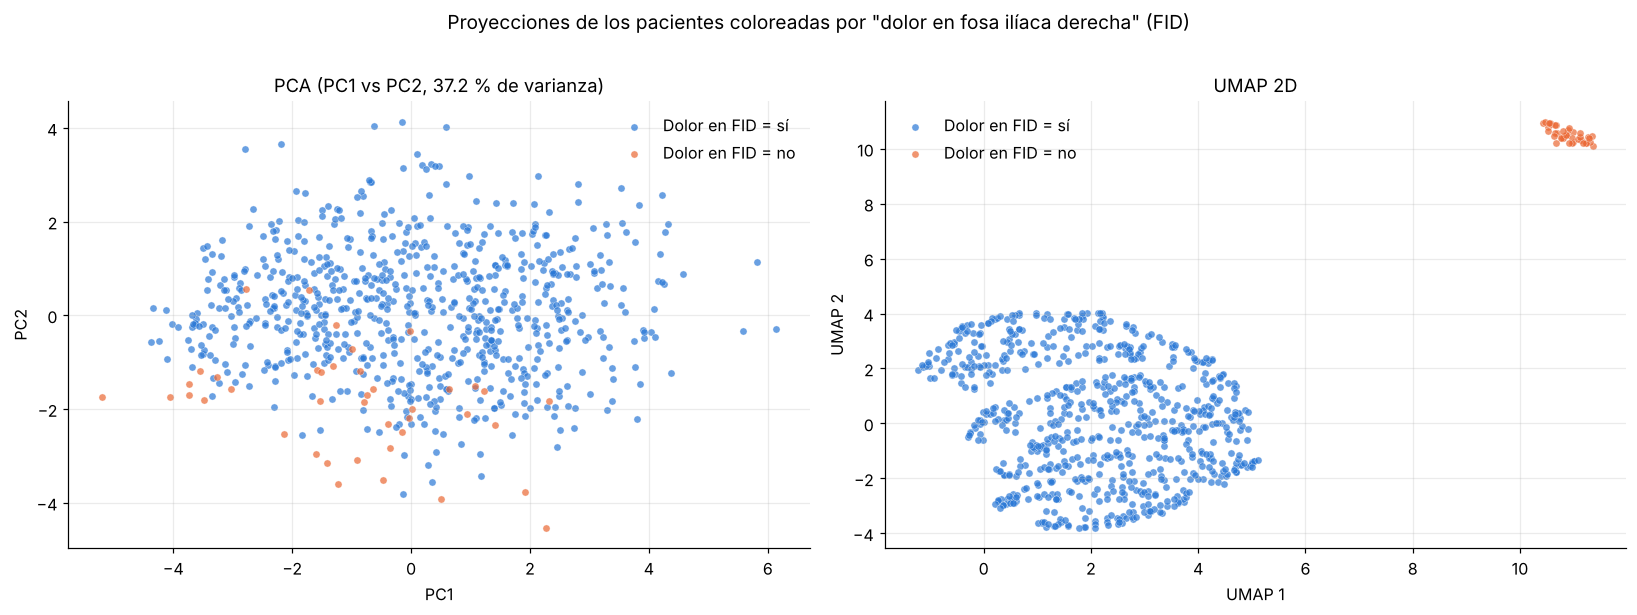

In [10]:
# Comparación visual de los dos espacios (los colores muestran UNA variable original, no el diagnóstico)
fid = X_imp['Lower_Right_Abd_Pain'].astype(int).values
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, Z, titulo, ejes in [(axes[0], X_pca[:, :2], f'PCA (PC1 vs PC2, {var_acum[1]:.1f} % de varianza)', ('PC1', 'PC2')),
                            (axes[1], X_umap, 'UMAP 2D', ('UMAP 1', 'UMAP 2'))]:
    for v, nombre, c in [(1, 'Dolor en FID = sí', COLORES[0]), (0, 'Dolor en FID = no', COLORES[1])]:
        ax.scatter(Z[fid == v, 0], Z[fid == v, 1], s=22, alpha=0.7, color=c, label=nombre,
                   edgecolors='white', linewidths=0.3)
    ax.set_title(titulo); ax.set_xlabel(ejes[0]); ax.set_ylabel(ejes[1]); ax.legend(frameon=False)
plt.suptitle('Proyecciones de los pacientes coloreadas por "dolor en fosa ilíaca derecha" (FID)', y=1.01)
plt.tight_layout(); plt.show()

**¿Qué diferencia hay entre los dos mapas?**
- **PCA** muestra una **nube continua**, sin grupos separados a simple vista. Los pacientes sin dolor en la FID quedan
  dispersos en el borde inferior izquierdo.
- **UMAP** muestra una **isla completamente aislada** formada **exactamente por los 41 pacientes sin dolor en la FID**, además de una
  masa principal con algunas subdivisiones.

**¿Por qué ocurre?** El 95 % de los pacientes tiene `Lower_Right_Abd_Pain = 1`. Al estandarizar, el valor 0 queda a unas
**4 desviaciones estándar** del resto. Como UMAP construye su mapa con los vecinos más cercanos, esos 41 pacientes solo
son vecinos entre sí y forman una isla. Es un efecto **geométrico** de una variable binaria muy desbalanceada, no
necesariamente un grupo clínico. Esto lo tendremos en cuenta al interpretar los clusters.

### 2.5 Funciones auxiliares

Para aplicar exactamente el mismo procedimiento en los cuatro experimentos definimos funciones reutilizables:
- `grafica_kdistancias`: curva de k-distancias y detección **automática** del codo (punto de máxima distancia a la recta que une los extremos de la curva, método *Kneedle*).
- `conteo_clusters`: número de objetos por cluster (y ruido).
- `evaluar_silueta`: `silhouette_score` global + `silhouette_samples` por cluster (gráfica y tabla).
- `perfil_clinico`: promedio de cada variable por cluster + validación con el diagnóstico real.

In [11]:
def detectar_codo(valores):
    # Codo = punto de la curva ordenada más alejado de la recta entre el primer y el último punto
    y = np.sort(valores); x = np.arange(len(y))
    p1, p2 = np.array([0, y[0]]), np.array([len(y) - 1, y[-1]])
    u = (p2 - p1) / np.linalg.norm(p2 - p1)
    puntos = np.c_[x, y] - p1
    dist = np.linalg.norm(puntos - np.outer(puntos @ u, u), axis=1)
    i = int(dist.argmax())
    return y[i], i, y

def grafica_kdistancias(Z, k, titulo):
    # kneighbors sobre los mismos datos incluye al propio punto, igual que min_samples en DBSCAN
    dist, _ = NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)
    eps, i, curva = detectar_codo(dist[:, -1])
    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    ax.plot(curva, color=COLORES[0], lw=2, label=f'Distancia al {k}° vecino (ordenada)')
    ax.axhline(eps, color=COLORES[1], ls='--', lw=1.4, label=f'ε elegido (codo) = {eps:.3f}')
    ax.scatter([i], [eps], s=90, color=COLORES[1], zorder=5, edgecolors='white', linewidths=1.5)
    ax.annotate('codo', xy=(i, eps), xytext=(i - len(curva) * 0.25, eps + (curva.max() - eps) * 0.45),
                arrowprops=dict(arrowstyle='->', color='#555'), fontsize=10)
    ax.set_xlabel('Pacientes ordenados por distancia'); ax.set_ylabel(f'Distancia al {k}° vecino')
    ax.set_title(titulo); ax.legend(frameon=False, loc='upper left')
    plt.tight_layout(); plt.show()
    return eps

def nombre_cluster(c):
    return 'Ruido (-1)' if c == -1 else f'Cluster {c}'

def color_cluster(c):
    return COLOR_RUIDO if c == -1 else COLORES[c % len(COLORES)]

def conteo_clusters(etiquetas):
    vc = pd.Series(etiquetas).value_counts().sort_index()
    tabla = pd.DataFrame({'Grupo': [nombre_cluster(c) for c in vc.index], 'Nº pacientes': vc.values,
                          '% del total': (vc.values / len(etiquetas) * 100).round(1)})
    n_cl = len([c for c in vc.index if c != -1])
    print(f"Clusters encontrados: {n_cl} | Pacientes como ruido: {(etiquetas == -1).sum()}")
    display(tabla)
    return n_cl

def evaluar_silueta(Z, etiquetas, titulo):
    # Silueta global y por cluster. El ruido (-1) se excluye: no es un cluster.
    mask = etiquetas != -1
    Zc, ec = Z[mask], etiquetas[mask]
    if len(set(ec)) < 2:
        print("Solo hay un cluster: la silueta no está definida."); return np.nan, None
    s_glob = silhouette_score(Zc, ec)
    s_ind = silhouette_samples(Zc, ec)
    print(f"silhouette_score global (sin ruido): {s_glob:.4f}")

    fig, ax = plt.subplots(figsize=(8.5, 5))
    y0 = 10
    for c in sorted(set(ec)):
        v = np.sort(s_ind[ec == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=color_cluster(c), alpha=0.85)
        ax.text(-0.02, y0 + len(v) / 2, f'C{c} (n={len(v)})', ha='right', va='center', fontsize=9)
        y0 += len(v) + 10
    ax.axvline(s_glob, color='#333', ls='--', lw=1.3, label=f'Promedio global = {s_glob:.3f}')
    ax.axvline(0, color='#999', lw=0.8)
    ax.set_xlim(min(-0.3, s_ind.min() - 0.05), 1); ax.set_yticks([])
    ax.set_xlabel('Coeficiente de silueta s(i)'); ax.set_title(titulo); ax.legend(frameon=False, loc='lower right')
    plt.tight_layout(); plt.show()

    tabla = pd.DataFrame({
        'Silueta media': pd.Series(s_ind).groupby(ec).mean(),
        'Mínimo': pd.Series(s_ind).groupby(ec).min(),
        '% puntos con s(i) < 0': pd.Series(s_ind < 0).groupby(ec).mean() * 100}).round(3)
    tabla.index = [nombre_cluster(c) for c in tabla.index]
    print("Evaluación de cada cluster con silhouette_samples:")
    display(tabla)
    return s_glob, tabla

def grafica_clusters(Z, etiquetas, titulo, ejes):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for c in sorted(set(etiquetas)):
        m = etiquetas == c
        ax.scatter(Z[m, 0], Z[m, 1], s=40 if c == -1 else 22, alpha=0.9 if c == -1 else 0.7,
                   color=color_cluster(c), marker='x' if c == -1 else 'o',
                   label=f'{nombre_cluster(c)} (n={m.sum()})', edgecolors='white' if c != -1 else None,
                   linewidths=0.3)
    ax.set_title(titulo); ax.set_xlabel(ejes[0]); ax.set_ylabel(ejes[1]); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

VARS_PERFIL = ['Age', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Appendix_Diameter',
               'Body_Temperature', 'WBC_Count', 'Neutrophil_Percentage', 'CRP',
               'Lower_Right_Abd_Pain', 'Migratory_Pain', 'Contralateral_Rebound_Tenderness',
               'Coughing_Pain', 'Nausea', 'Loss_of_Appetite']

def perfil_clinico(etiquetas):
    # Perfil promedio (datos imputados, en unidades originales) + validación con el diagnóstico
    d = X_imp.copy(); d['Cluster'] = etiquetas
    perfil = d.groupby('Cluster')[VARS_PERFIL].mean()
    binarias = ['Lower_Right_Abd_Pain', 'Migratory_Pain', 'Contralateral_Rebound_Tenderness',
                'Coughing_Pain', 'Nausea', 'Loss_of_Appetite']
    perfil[binarias] = perfil[binarias] * 100   # binarias como % de pacientes con el síntoma
    perfil = perfil.rename(columns={b: f'% {b}' for b in binarias})
    perfil.insert(0, 'Nº pacientes', d['Cluster'].value_counts().sort_index())
    validos = y_true.notna()
    tasa = (y_true[validos] == 'appendicitis').groupby(np.asarray(etiquetas)[validos.values]).mean() * 100
    perfil.insert(1, '% con apendicitis', tasa)
    perfil.index = [nombre_cluster(c) for c in perfil.index]
    total = d[VARS_PERFIL].mean()
    total[binarias] = total[binarias] * 100
    total = total.rename({b: f'% {b}' for b in binarias})
    total['Nº pacientes'] = len(d)
    total['% con apendicitis'] = (y_true[validos] == 'appendicitis').mean() * 100
    perfil = pd.concat([perfil, total[perfil.columns].to_frame('TODOS').T])
    print("Perfil clínico promedio por cluster (síntomas en % de pacientes):")
    display(perfil.T.round(2))
    print("\nValidación externa (tabla cruzada con el diagnóstico real):")
    ct = pd.crosstab(pd.Series(np.asarray(etiquetas)[validos.values], name='Cluster').map(nombre_cluster),
                     pd.Series(y_true[validos].values, name='Diagnóstico real'), margins=True, margins_name='Total')
    display(ct)
    return perfil

resultados = []   # aquí se guarda el resumen de cada experimento para el Punto 5

def registrar(espacio, algoritmo, parametros, etiquetas, sil, perfil):
    tasas = perfil.drop(index='TODOS')
    tasas = tasas[tasas.index != 'Ruido (-1)']['% con apendicitis']
    resultados.append({'Espacio': espacio, 'Algoritmo': algoritmo, 'Parámetros': parametros,
                       'Nº clusters': len(set(etiquetas) - {-1}), 'Ruido': int((etiquetas == -1).sum()),
                       'Silueta global': round(sil, 3),
                       'Tamaños': ' / '.join(str(v) for v in pd.Series(etiquetas[etiquetas != -1]).value_counts().sort_index().values),
                       '% apendicitis por cluster': ' / '.join(f'{v:.0f}%' for v in tasas.values)})

print("Funciones definidas.")

Funciones definidas.


---
## Punto 3 — Clusterización con DBSCAN (2.5 pts)

### ¿Cómo funciona DBSCAN?
DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) busca **zonas densas** de puntos:
- **Punto núcleo:** tiene al menos `min_samples` puntos (contándose a sí mismo) dentro de un radio **ε**.
- **Punto frontera:** está dentro del radio ε de un punto núcleo, pero no tiene suficientes vecinos.
- **Ruido (-1):** no es núcleo ni frontera. **No se fuerza a ningún grupo.**

### ¿Cómo elegimos los parámetros?
- **`min_samples = 10`**: la regla práctica es usar al menos *dimensiones + 1*; el espacio PCA tiene
  {n_comp} dimensiones → 10. Usamos el mismo valor en UMAP para que ambos experimentos sean comparables
  (valores más bajos en UMAP fragmentan el mapa en decenas de micro-grupos).
- **ε (épsilon)**: con la **gráfica de k-distancias**, usando **k = min_samples**:
  1. Para cada paciente calculamos la distancia a su k-ésimo vecino más cercano.
  2. Ordenamos esas distancias de menor a mayor.
  3. El **codo** (donde la curva empieza a subir bruscamente) separa las zonas densas de los puntos aislados.
     Lo detectamos de forma objetiva como el punto más alejado de la recta que une los extremos de la curva.

In [12]:
MIN_SAMPLES = 10
print(f"min_samples = {MIN_SAMPLES} (dimensiones del espacio PCA = {X_pca.shape[1]} → regla D + 1 = {X_pca.shape[1] + 1})")

min_samples = 10 (dimensiones del espacio PCA = 9 → regla D + 1 = 10)


### 3.1 Experimento 1: DBSCAN en el espacio PCA

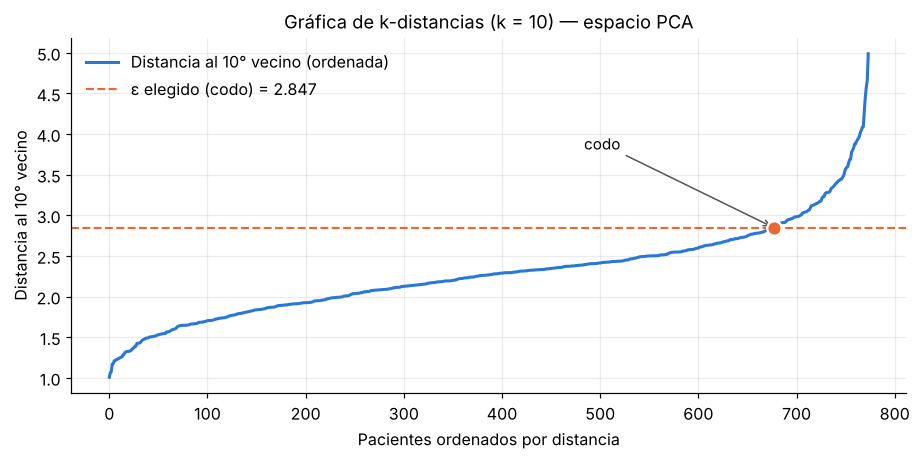

ε seleccionado en el codo: 2.847


In [13]:
# Gráfica de k-distancias para seleccionar ε
eps_pca = grafica_kdistancias(X_pca, MIN_SAMPLES, 'Gráfica de k-distancias (k = {}) — espacio PCA'.format(MIN_SAMPLES))
print(f"ε seleccionado en el codo: {eps_pca:.3f}")

In [14]:
# Sensibilidad: ¿qué pasa si movemos ε alrededor del codo?
filas = []
for f in [0.8, 0.9, 1.0, 1.1, 1.2]:
    e = eps_pca * f
    et = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(X_pca)
    m = et != -1
    n = len(set(et[m]))
    filas.append({'ε': round(e, 3), 'factor': f, 'Nº clusters': n, 'Ruido': int((~m).sum()),
                  'Silueta (sin ruido)': round(silhouette_score(X_pca[m], et[m]), 3) if n > 1 else None})
display(pd.DataFrame(filas))

,ε,factor,Nº clusters,Ruido,Silueta (sin ruido)
0,2.277,0.8,2,160,0.172
1,2.562,0.9,2,62,0.204
2,2.847,1.0,2,24,0.237
3,3.131,1.1,1,9,NaN
4,3.416,1.2,1,4,NaN


In [15]:
# Modelo DBSCAN final y número de objetos por cluster
db_pca = DBSCAN(eps=eps_pca, min_samples=MIN_SAMPLES)
etiq_db_pca = db_pca.fit_predict(X_pca)
conteo_clusters(etiq_db_pca)

Clusters encontrados: 2 | Pacientes como ruido: 24


,Grupo,Nº pacientes,% del total
0,Ruido (-1),24,3.1
1,Cluster 0,717,92.6
2,Cluster 1,33,4.3


2

silhouette_score global (sin ruido): 0.2373


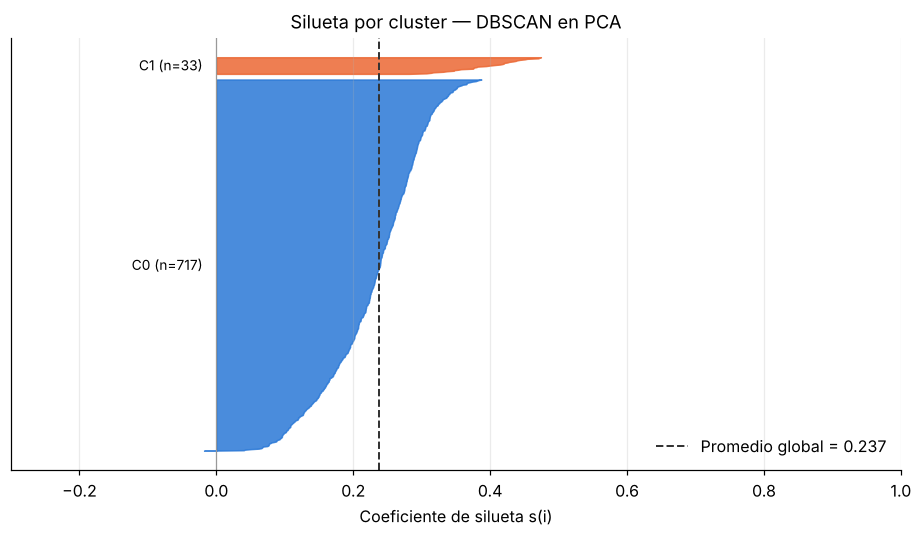

Evaluación de cada cluster con silhouette_samples:


,Silueta media,Mínimo,% puntos con s(i) < 0
Cluster 0,0.230,-0.018,0.139
Cluster 1,0.393,0.281,0.000


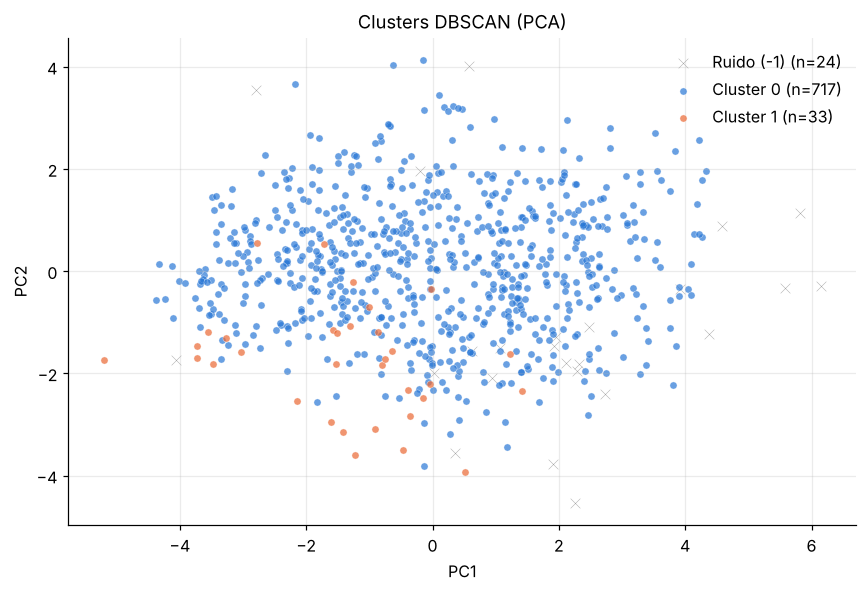

In [16]:
# Evaluación: silhouette_score global y silhouette_samples por cluster
sil_db_pca, tabla_sil_db_pca = evaluar_silueta(X_pca, etiq_db_pca, 'Silueta por cluster — DBSCAN en PCA')
grafica_clusters(X_pca[:, :2], etiq_db_pca, 'Clusters DBSCAN (PCA)', ('PC1', 'PC2'))

In [17]:
# Interpretación: perfil clínico de cada cluster y validación con el diagnóstico
perfil_db_pca = perfil_clinico(etiq_db_pca)
registrar('PCA', 'DBSCAN', f'ε={eps_pca:.3f}, min_samples={MIN_SAMPLES}', etiq_db_pca, sil_db_pca, perfil_db_pca)

Perfil clínico promedio por cluster (síntomas en % de pacientes):


,Ruido (-1),Cluster 0,Cluster 1,TODOS
Nº pacientes,24.00,717.00,33.00,774.00
% con apendicitis,91.67,59.55,27.27,59.17
Age,9.98,11.44,10.21,11.34
Alvarado_Score,6.54,6.00,3.88,5.93
Paedriatic_Appendicitis_Score,6.08,5.31,3.03,5.24
Appendix_Diameter,9.17,7.64,7.08,7.67
Body_Temperature,38.10,37.41,37.18,37.42
WBC_Count,17.45,12.58,11.97,12.71
Neutrophil_Percentage,78.30,72.07,72.52,72.28
CRP,191.12,26.56,18.58,31.32



Validación externa (tabla cruzada con el diagnóstico real):


Diagnóstico real,appendicitis,no appendicitis,Total
Cluster,,,
Cluster 0,427,290,717
Cluster 1,9,24,33
Ruido (-1),22,2,24
Total,458,316,774


#### Interpretación — Experimento 1 (DBSCAN en PCA)
- **Parámetros:** ε = 2.847 (codo de la curva de k-distancias) y `min_samples` = 10. La tabla de sensibilidad muestra que con
  ε un 10 % mayor todo se une en un solo cluster. El codo está justo en el límite donde todavía se distinguen grupos.
- **Silueta global = 0.237** (separación débil). Por cluster: C0 = 0.230 y C1 = 0.393. Casi ningún punto tiene silueta negativa,
  así que las asignaciones son coherentes, aunque los grupos no están muy separados.

| Grupo | n | Perfil | % apendicitis |
|---|---|---|---|
| **Cluster 0: masa principal** | 717 | Todos con dolor en FID y valores intermedios en todo | 59.6 % (≈ la base) |
| **Cluster 1: sin dolor en FID** | 33 | 0 % dolor en FID, 0 % dolor migratorio, scores bajos (Alvarado 3.9) | **27.3 %** |
| **Ruido (−1): casos extremos** | 24 | **PCR media 191 mg/L**, leucocitos 17.5, fiebre 38.1 °C, apéndice 9.2 mm | **91.7 %** |

**Lo más valioso de este experimento es el ruido.** DBSCAN no forzó a estos 24 pacientes en ningún grupo porque están lejos
de la zona densa, y resultaron ser **casi todos apendicitis con marcadores inflamatorios muy elevados**, compatibles con
apendicitis complicada. En urgencias, el ruido de DBSCAN funciona como una **alerta de caso grave o atípico**.

### 3.2 Experimento 2: DBSCAN en el espacio UMAP

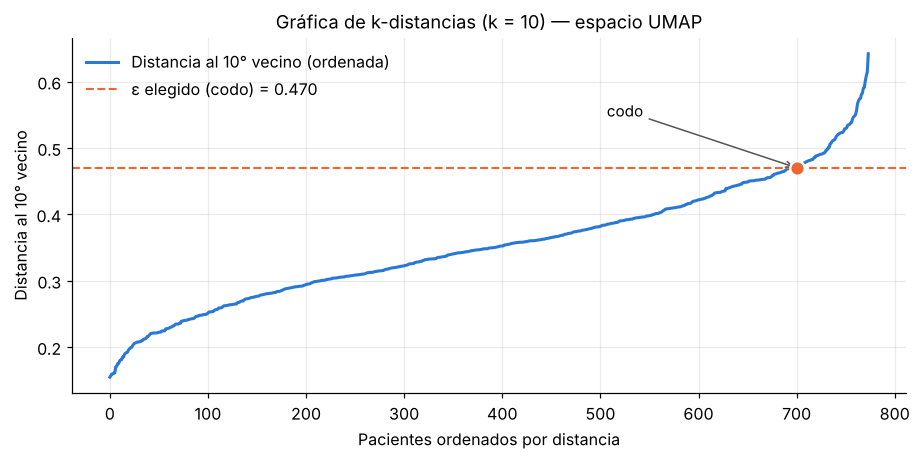

ε seleccionado en el codo: 0.470


In [18]:
# Gráfica de k-distancias para seleccionar ε
eps_umap = grafica_kdistancias(X_umap, MIN_SAMPLES, 'Gráfica de k-distancias (k = {}) — espacio UMAP'.format(MIN_SAMPLES))
print(f"ε seleccionado en el codo: {eps_umap:.3f}")

In [19]:
# Sensibilidad: ¿qué pasa si movemos ε alrededor del codo?
filas = []
for f in [0.8, 0.9, 1.0, 1.1, 1.2]:
    e = eps_umap * f
    et = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(X_umap)
    m = et != -1
    n = len(set(et[m]))
    filas.append({'ε': round(e, 3), 'factor': f, 'Nº clusters': n, 'Ruido': int((~m).sum()),
                  'Silueta (sin ruido)': round(silhouette_score(X_umap[m], et[m]), 3) if n > 1 else None})
display(pd.DataFrame(filas))

,ε,factor,Nº clusters,Ruido,Silueta (sin ruido)
0,0.376,0.8,16,70,0.452
1,0.423,0.9,10,24,0.287
2,0.470,1.0,5,4,0.181
3,0.517,1.1,2,1,0.761
4,0.564,1.2,2,0,0.761


In [20]:
# Modelo DBSCAN final y número de objetos por cluster
db_umap = DBSCAN(eps=eps_umap, min_samples=MIN_SAMPLES)
etiq_db_umap = db_umap.fit_predict(X_umap)
conteo_clusters(etiq_db_umap)

Clusters encontrados: 5 | Pacientes como ruido: 4


,Grupo,Nº pacientes,% del total
0,Ruido (-1),4,0.5
1,Cluster 0,544,70.3
2,Cluster 1,36,4.7
3,Cluster 2,115,14.9
4,Cluster 3,41,5.3
5,Cluster 4,34,4.4


5

silhouette_score global (sin ruido): 0.1807


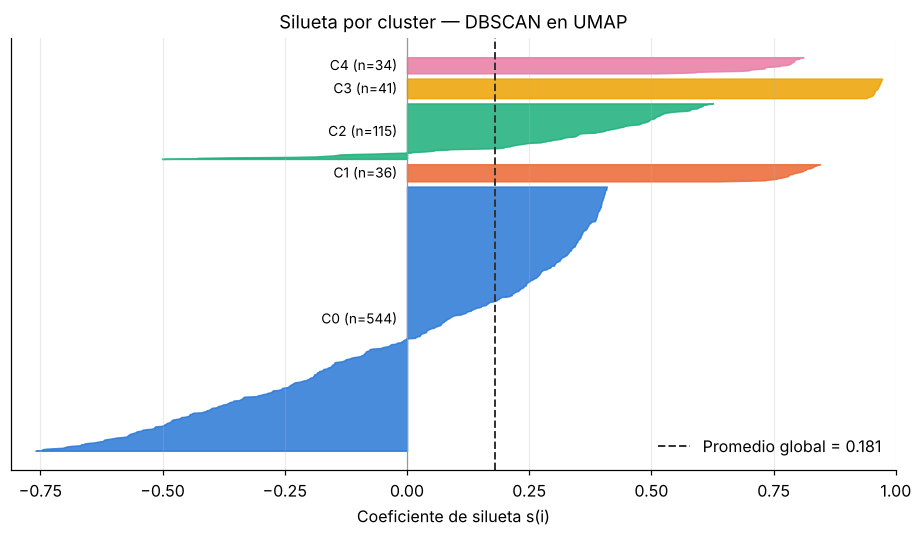

Evaluación de cada cluster con silhouette_samples:


,Silueta media,Mínimo,% puntos con s(i) < 0
Cluster 0,0.016,-0.760,42.647
Cluster 1,0.789,0.638,0.000
Cluster 2,0.326,-0.501,11.304
Cluster 3,0.960,0.940,0.000
Cluster 4,0.737,0.510,0.000


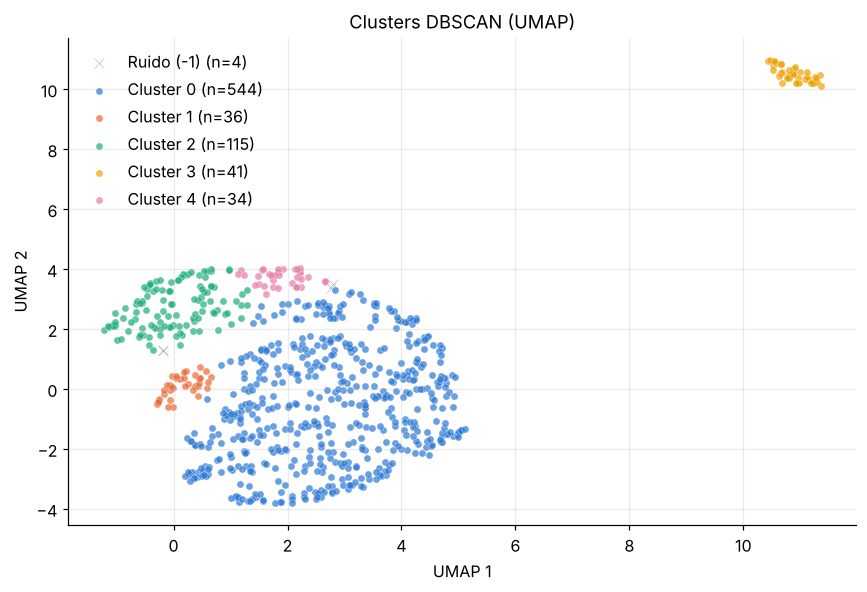

In [21]:
# Evaluación: silhouette_score global y silhouette_samples por cluster
sil_db_umap, tabla_sil_db_umap = evaluar_silueta(X_umap, etiq_db_umap, 'Silueta por cluster — DBSCAN en UMAP')
grafica_clusters(X_umap, etiq_db_umap, 'Clusters DBSCAN (UMAP)', ('UMAP 1', 'UMAP 2'))

In [22]:
# Interpretación: perfil clínico de cada cluster y validación con el diagnóstico
perfil_db_umap = perfil_clinico(etiq_db_umap)
registrar('UMAP', 'DBSCAN', f'ε={eps_umap:.3f}, min_samples={MIN_SAMPLES}', etiq_db_umap, sil_db_umap, perfil_db_umap)

Perfil clínico promedio por cluster (síntomas en % de pacientes):


,Ruido (-1),Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,TODOS
Nº pacientes,4.00,544.00,36.00,115.00,41.00,34.00,774.00
% con apendicitis,75.00,62.32,47.22,45.22,36.59,94.12,59.17
Age,10.31,11.11,12.47,12.61,10.14,11.08,11.34
Alvarado_Score,4.50,6.29,4.42,4.86,4.10,7.62,5.93
Paedriatic_Appendicitis_Score,5.75,5.25,3.78,5.66,3.29,7.53,5.24
Appendix_Diameter,8.00,7.89,6.91,6.78,7.11,8.51,7.67
Body_Temperature,36.90,37.53,36.88,37.07,37.33,37.49,37.42
WBC_Count,11.70,13.56,8.10,9.27,12.84,15.55,12.71
Neutrophil_Percentage,71.88,73.98,60.33,64.07,74.36,83.05,72.28
CRP,5.00,37.17,6.76,8.58,46.47,25.47,31.32



Validación externa (tabla cruzada con el diagnóstico real):


Diagnóstico real,appendicitis,no appendicitis,Total
Cluster,,,
Cluster 0,339,205,544
Cluster 1,17,19,36
Cluster 2,52,63,115
Cluster 3,15,26,41
Cluster 4,32,2,34
Ruido (-1),3,1,4
Total,458,316,774


#### Interpretación — Experimento 2 (DBSCAN en UMAP)
- **Parámetros:** ε = 0.470 (codo) y `min_samples` = 10. La **tabla de sensibilidad** muestra que UMAP es muy inestable con DBSCAN:
  con 0.8·ε salen 16 clusters y con 1.1·ε solo 2 (silueta 0.76, que es simplemente la isla de 41 pacientes frente al resto).
- **Silueta global = 0.181**, pero muy desigual entre clusters, como muestra `silhouette_samples`:
  - C1, C3 y C4 tienen siluetas altas (0.79, 0.96 y 0.74): son grupos compactos y bien separados.
  - **C0 tiene silueta ≈ 0.02 y el 43 % de sus pacientes con s(i) < 0**. No es un grupo homogéneo, sino una “masa residual”
    donde DBSCAN unió zonas de densidad distinta.

| Grupo | n | Perfil | % apendicitis |
|---|---|---|---|
| **C4: cuadro clásico con irritación peritoneal** | 34 | Alvarado 7.6, PAS 7.5, rebote 88 %, dolor al toser 100 %, náusea 85 %, neutrófilos 83 % | **94.1 %** |
| C0: masa principal | 544 | Valores intermedios | 62.3 % |
| C1: dolor migratorio sin inflamación | 36 | Dolor migratorio 100 %, leucocitos 8.1, PCR 6.8 | 47.2 % |
| C2: dolor al toser sin inflamación | 115 | Dolor al toser 100 %, leucocitos 9.3, PCR 8.6 | 45.2 % |
| C3: sin dolor en FID | 41 | 0 % dolor en FID (la isla de UMAP) | 36.6 % |
| Ruido | 4 | — | — |

**Lectura clínica:** DBSCAN en UMAP encontró el grupo **más “puro” de todos los experimentos (C4, 94 % de apendicitis)**.
Los demás grupos pequeños se definen por **un síntoma binario concreto** (dolor migratorio, dolor al toser, dolor en FID).
UMAP agrupa a los pacientes que comparten exactamente la misma combinación de síntomas sí/no.

---
## Punto 4 — Clusterización jerárquica aglomerativa (2.5 pts)

### ¿Cómo funciona?
1. Cada paciente empieza como su propio grupo.
2. En cada paso se unen los dos grupos más parecidos, hasta que solo queda uno.
3. Usamos el **enlace de Ward**: en cada unión elige la que **menos aumenta la varianza interna**, por lo que
   produce grupos compactos.
4. El **dendrograma** muestra la historia de uniones; la altura de cada unión indica cuán distintos eran
   los grupos fusionados. **Cortar** el árbol con una línea horizontal define el número de clusters.

### ¿Cómo elegimos el número de clusters k?
Calculamos el `silhouette_score` para k = 2…8 y elegimos el k con mayor silueta. La línea de corte del
dendrograma se dibuja **a la altura que produce exactamente ese k** (entre la unión k y la k−1).

### 4.1 Experimento 3: Aglomerativo (Ward) en el espacio PCA

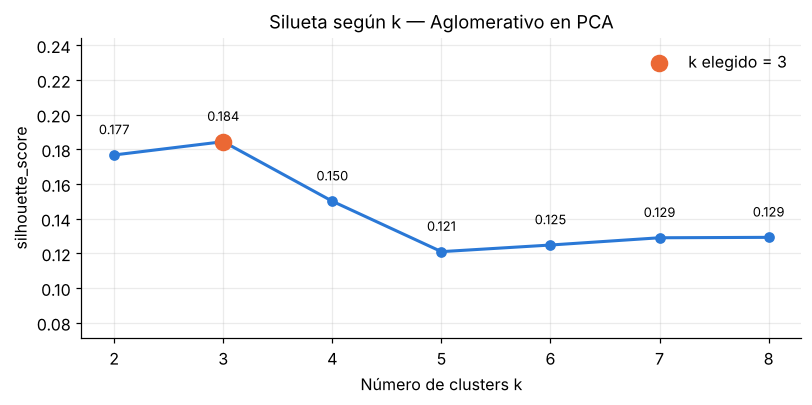

In [23]:
# Selección de k con el silhouette_score
rango_k = range(2, 9)
sil_k_pca = [silhouette_score(X_pca, AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_pca))
               for k in rango_k]
k_pca = list(rango_k)[int(np.argmax(sil_k_pca))]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(list(rango_k), sil_k_pca, marker='o', color=COLORES[0], lw=2)
ax.scatter([k_pca], [max(sil_k_pca)], s=110, color=COLORES[1], zorder=5, label=f'k elegido = {k_pca}')
for k, s in zip(rango_k, sil_k_pca):
    ax.text(k, s + 0.012, f'{s:.3f}', ha='center', fontsize=8.5)
ax.set_xlabel('Número de clusters k'); ax.set_ylabel('silhouette_score')
ax.set_title('Silueta según k — Aglomerativo en PCA'); ax.legend(frameon=False)
ax.set_ylim(min(sil_k_pca) - 0.05, max(sil_k_pca) + 0.06)
plt.tight_layout(); plt.show()

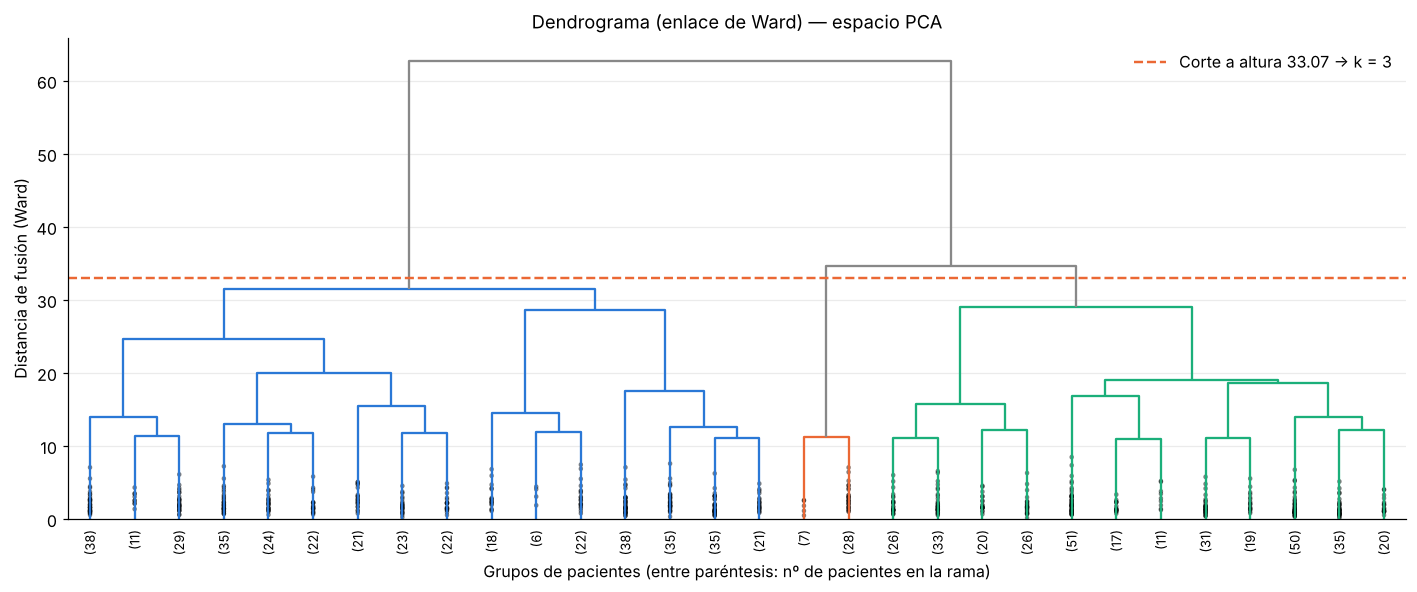

Nota: los colores del dendrograma solo distinguen las ramas bajo el corte; no corresponden al número de cluster.


In [24]:
# Dendrograma con la línea de corte que produce k_pca clusters
Z_pca = linkage(X_pca, method='ward')
alturas = Z_pca[:, 2]
corte_pca = (alturas[-k_pca] + alturas[-(k_pca - 1)]) / 2   # entre la unión k y la k-1

plt.figure(figsize=(13, 5.5))
dendrogram(Z_pca, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8.5,
           show_contracted=True, color_threshold=corte_pca, above_threshold_color='#888')
plt.axhline(corte_pca, color=COLORES[1], ls='--', lw=1.6, label=f'Corte a altura {corte_pca:.2f} → k = {k_pca}')
plt.title('Dendrograma (enlace de Ward) — espacio PCA')
plt.xlabel('Grupos de pacientes (entre paréntesis: nº de pacientes en la rama)')
plt.ylabel('Distancia de fusión (Ward)'); plt.legend(frameon=False)
plt.grid(axis='x', visible=False); plt.tight_layout(); plt.show()
print('Nota: los colores del dendrograma solo distinguen las ramas bajo el corte; no corresponden al número de cluster.')

In [25]:
# Modelo final y número de objetos por cluster
agg_pca = AgglomerativeClustering(n_clusters=k_pca, linkage='ward')
etiq_agg_pca = agg_pca.fit_predict(X_pca)
conteo_clusters(etiq_agg_pca)

Clusters encontrados: 3 | Pacientes como ruido: 0


,Grupo,Nº pacientes,% del total
0,Cluster 0,400,51.7
1,Cluster 1,339,43.8
2,Cluster 2,35,4.5


3

silhouette_score global (sin ruido): 0.1844


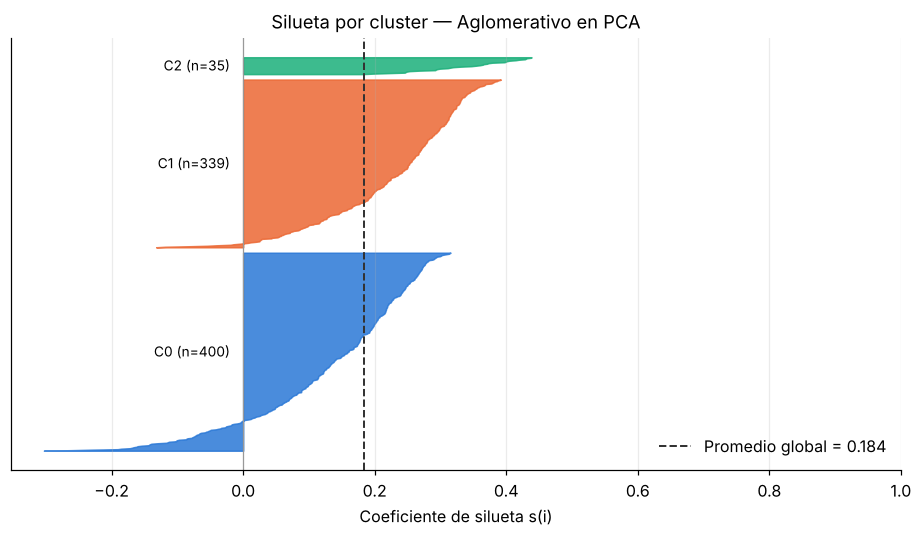

Evaluación de cada cluster con silhouette_samples:


,Silueta media,Mínimo,% puntos con s(i) < 0
Cluster 0,0.133,-0.303,15.25
Cluster 1,0.229,-0.132,2.36
Cluster 2,0.338,0.182,0.00


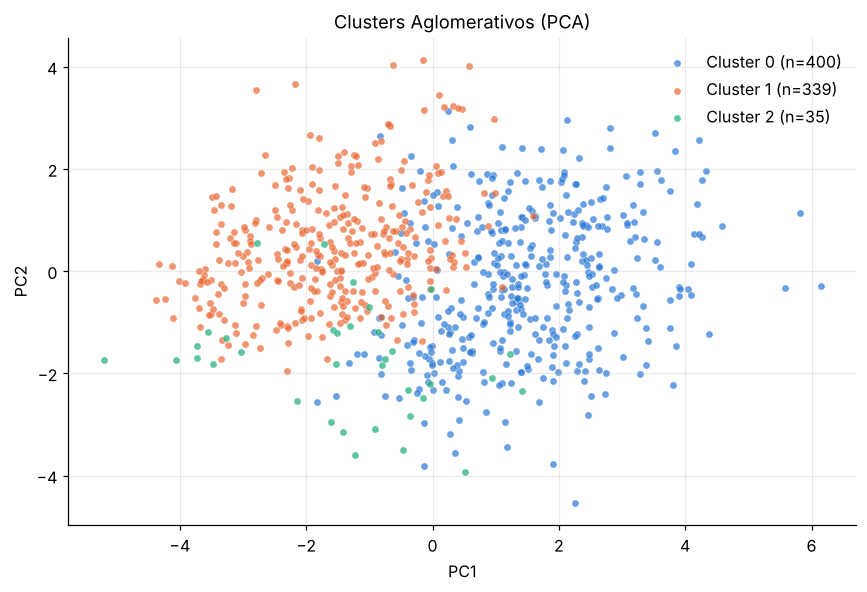

In [26]:
# Evaluación: silhouette_score global y silhouette_samples por cluster
sil_agg_pca, tabla_sil_agg_pca = evaluar_silueta(X_pca, etiq_agg_pca, 'Silueta por cluster — Aglomerativo en PCA')
grafica_clusters(X_pca[:, :2], etiq_agg_pca, 'Clusters Aglomerativos (PCA)', ('PC1', 'PC2'))

In [27]:
# Interpretación: perfil clínico y validación con el diagnóstico
perfil_agg_pca = perfil_clinico(etiq_agg_pca)
registrar('PCA', 'Aglomerativo (Ward)', f'k={k_pca}', etiq_agg_pca, sil_agg_pca, perfil_agg_pca)

Perfil clínico promedio por cluster (síntomas en % de pacientes):


,Cluster 0,Cluster 1,Cluster 2,TODOS
Nº pacientes,400.00,339.00,35.00,774.00
% con apendicitis,78.25,40.12,25.71,59.17
Age,10.23,12.79,10.05,11.34
Alvarado_Score,7.41,4.39,3.80,5.93
Paedriatic_Appendicitis_Score,6.33,4.17,3.06,5.24
Appendix_Diameter,8.30,7.00,6.97,7.67
Body_Temperature,37.77,37.02,37.16,37.42
WBC_Count,15.90,9.01,11.99,12.71
Neutrophil_Percentage,80.66,62.34,72.80,72.28
CRP,52.02,8.32,17.58,31.32



Validación externa (tabla cruzada con el diagnóstico real):


Diagnóstico real,appendicitis,no appendicitis,Total
Cluster,,,
Cluster 0,313,87,400
Cluster 1,136,203,339
Cluster 2,9,26,35
Total,458,316,774


#### Interpretación — Experimento 3 (Ward en PCA)
- **Elección de k:** la silueta es máxima con **k = 3** (0.184). En el dendrograma, la línea de corte a 33.07 cruza exactamente 3
  ramas. Por encima de ese corte las uniones son mucho más costosas (≈ 35 y ≈ 63), lo que confirma la división.
- **Silueta global = 0.184 (baja).** Por cluster: C0 = 0.133, C1 = 0.229 y C2 = 0.338. Los grupos se tocan en sus bordes
  (el 15 % de C0 tiene silueta negativa), cosa esperable en una nube continua como la de PCA.

| Grupo | n | Perfil | % apendicitis |
|---|---|---|---|
| **C0: perfil inflamatorio** | 400 | Alvarado 7.4, leucocitos 15.9, neutrófilos 80.7 %, PCR 52, temperatura 37.8 °C, náusea 75 %, edad media 10.2 años | **78.3 %** |
| **C1: perfil de baja inflamación** | 339 | Alvarado 4.4, leucocitos 9.0, neutrófilos 62.3 %, PCR 8.3, edad media 12.8 años | **40.1 %** |
| **C2: sin dolor en FID** | 35 | 0 % dolor en FID, scores bajos | **25.7 %** |

**Este es el experimento con mayor sentido clínico.** Aunque su silueta es baja, Ward dividió a los pacientes por el
**eje de inflamación (PC1)** en tres niveles de riesgo: 78 %, 40 % y 26 % de apendicitis. Sin ver el diagnóstico, el algoritmo
reconstruyó la lógica de los scores clínicos.

### 4.2 Experimento 4: Aglomerativo (Ward) en el espacio UMAP

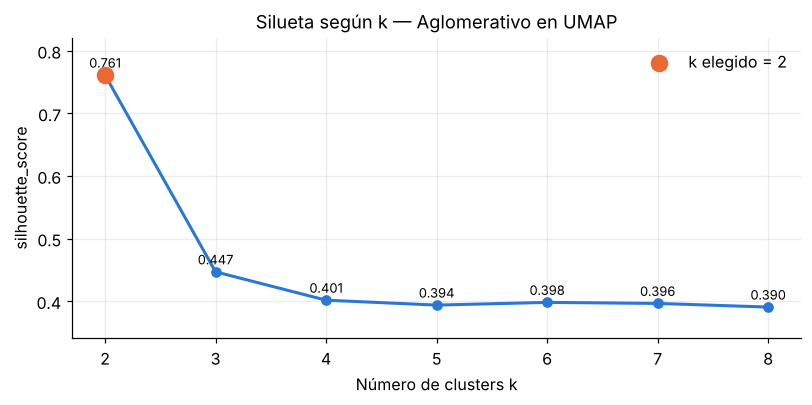

In [28]:
# Selección de k con el silhouette_score
rango_k = range(2, 9)
sil_k_umap = [silhouette_score(X_umap, AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_umap))
               for k in rango_k]
k_umap = list(rango_k)[int(np.argmax(sil_k_umap))]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(list(rango_k), sil_k_umap, marker='o', color=COLORES[0], lw=2)
ax.scatter([k_umap], [max(sil_k_umap)], s=110, color=COLORES[1], zorder=5, label=f'k elegido = {k_umap}')
for k, s in zip(rango_k, sil_k_umap):
    ax.text(k, s + 0.012, f'{s:.3f}', ha='center', fontsize=8.5)
ax.set_xlabel('Número de clusters k'); ax.set_ylabel('silhouette_score')
ax.set_title('Silueta según k — Aglomerativo en UMAP'); ax.legend(frameon=False)
ax.set_ylim(min(sil_k_umap) - 0.05, max(sil_k_umap) + 0.06)
plt.tight_layout(); plt.show()

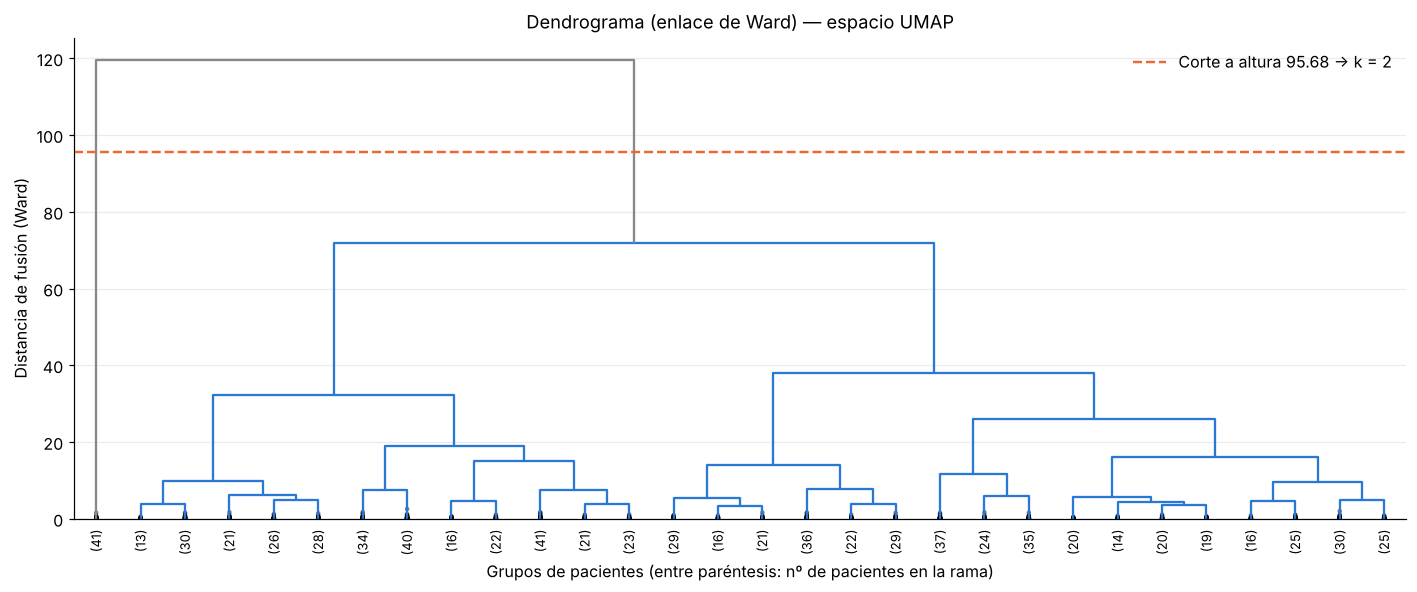

Nota: los colores del dendrograma solo distinguen las ramas bajo el corte; no corresponden al número de cluster.


In [29]:
# Dendrograma con la línea de corte que produce k_umap clusters
Z_umap = linkage(X_umap, method='ward')
alturas = Z_umap[:, 2]
corte_umap = (alturas[-k_umap] + alturas[-(k_umap - 1)]) / 2   # entre la unión k y la k-1

plt.figure(figsize=(13, 5.5))
dendrogram(Z_umap, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8.5,
           show_contracted=True, color_threshold=corte_umap, above_threshold_color='#888')
plt.axhline(corte_umap, color=COLORES[1], ls='--', lw=1.6, label=f'Corte a altura {corte_umap:.2f} → k = {k_umap}')
plt.title('Dendrograma (enlace de Ward) — espacio UMAP')
plt.xlabel('Grupos de pacientes (entre paréntesis: nº de pacientes en la rama)')
plt.ylabel('Distancia de fusión (Ward)'); plt.legend(frameon=False)
plt.grid(axis='x', visible=False); plt.tight_layout(); plt.show()
print('Nota: los colores del dendrograma solo distinguen las ramas bajo el corte; no corresponden al número de cluster.')

In [30]:
# Modelo final y número de objetos por cluster
agg_umap = AgglomerativeClustering(n_clusters=k_umap, linkage='ward')
etiq_agg_umap = agg_umap.fit_predict(X_umap)
conteo_clusters(etiq_agg_umap)

Clusters encontrados: 2 | Pacientes como ruido: 0


,Grupo,Nº pacientes,% del total
0,Cluster 0,733,94.7
1,Cluster 1,41,5.3


2

silhouette_score global (sin ruido): 0.7610


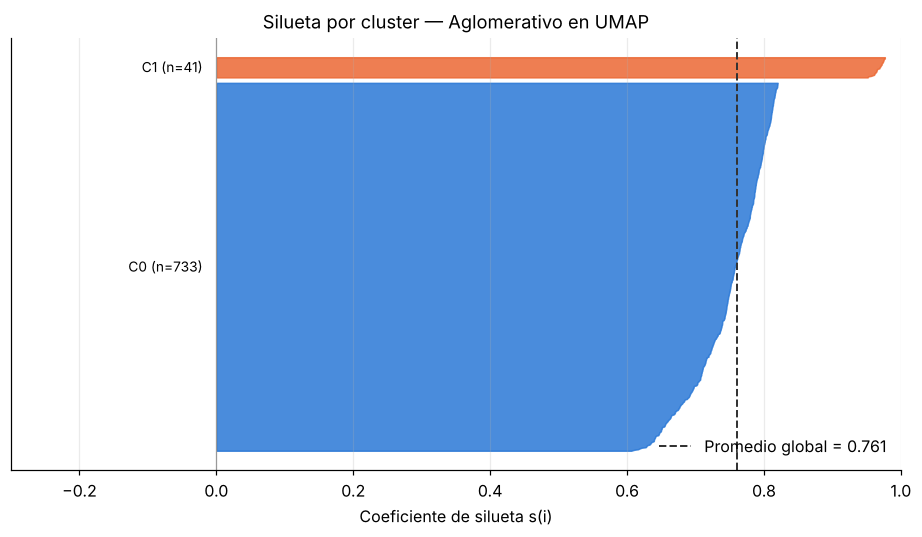

Evaluación de cada cluster con silhouette_samples:


,Silueta media,Mínimo,% puntos con s(i) < 0
Cluster 0,0.749,0.606,0.0
Cluster 1,0.967,0.951,0.0


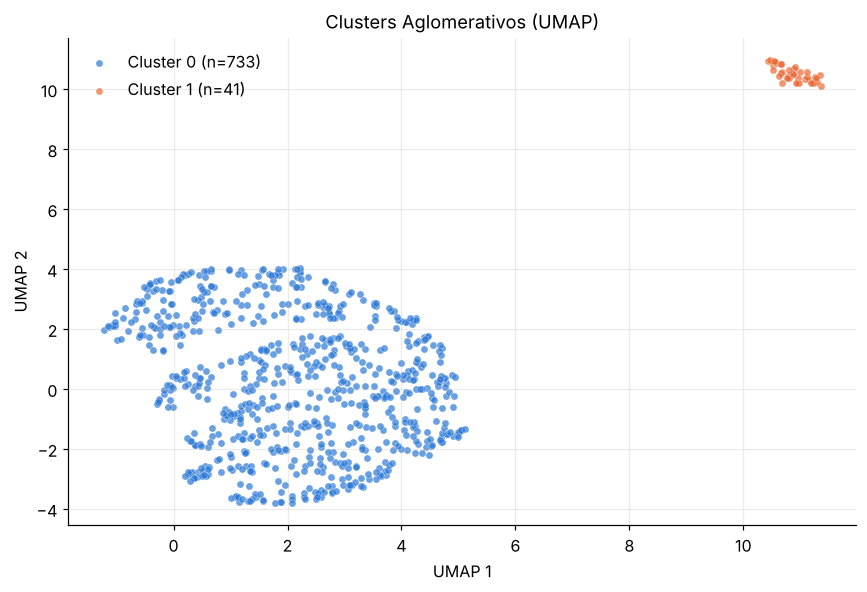

In [31]:
# Evaluación: silhouette_score global y silhouette_samples por cluster
sil_agg_umap, tabla_sil_agg_umap = evaluar_silueta(X_umap, etiq_agg_umap, 'Silueta por cluster — Aglomerativo en UMAP')
grafica_clusters(X_umap, etiq_agg_umap, 'Clusters Aglomerativos (UMAP)', ('UMAP 1', 'UMAP 2'))

In [32]:
# Interpretación: perfil clínico y validación con el diagnóstico
perfil_agg_umap = perfil_clinico(etiq_agg_umap)
registrar('UMAP', 'Aglomerativo (Ward)', f'k={k_umap}', etiq_agg_umap, sil_agg_umap, perfil_agg_umap)

Perfil clínico promedio por cluster (síntomas en % de pacientes):


,Cluster 0,Cluster 1,TODOS
Nº pacientes,733.00,41.00,774.00
% con apendicitis,60.44,36.59,59.17
Age,11.41,10.14,11.34
Alvarado_Score,6.03,4.10,5.93
Paedriatic_Appendicitis_Score,5.35,3.29,5.24
Appendix_Diameter,7.70,7.11,7.67
Body_Temperature,37.42,37.33,37.42
WBC_Count,12.70,12.84,12.71
Neutrophil_Percentage,72.17,74.36,72.28
CRP,30.47,46.47,31.32



Validación externa (tabla cruzada con el diagnóstico real):


Diagnóstico real,appendicitis,no appendicitis,Total
Cluster,,,
Cluster 0,443,290,733
Cluster 1,15,26,41
Total,458,316,774


#### Interpretación — Experimento 4 (Ward en UMAP)
- **Elección de k:** la silueta es máxima con **k = 2**. En el dendrograma, la línea de corte a 95.68 cruza 2 ramas: la isla de
  41 pacientes se une al resto solo al final, a una altura de ≈ 120.
- **Silueta global = 0.761 (muy alta).** Por cluster: C0 = 0.749 y C1 = 0.967, sin ningún punto negativo.

| Grupo | n | Perfil | % apendicitis |
|---|---|---|---|
| C0 | 733 | 100 % con dolor en FID | 60.4 % |
| C1 | 41 | 0 % con dolor en FID (la isla de UMAP) | 36.6 % |

**Una silueta alta no significa un buen resultado clínico.** La partición es geométricamente perfecta, pero solo reproduce
**una variable** (dolor en FID). El cluster grande tiene prácticamente la misma tasa de apendicitis que toda la población
(60.4 % frente a 59.2 %), así que no ayuda a distinguir a los pacientes. Ward en UMAP “descubrió” lo que ya sabíamos del EDA.

---
## Punto 5 — Conclusiones generales comparando los experimentos (1 pt)

In [33]:
resumen = pd.DataFrame(resultados)
display(resumen)

# Coincidencia entre particiones (Adjusted Rand Index: 1 = idénticas, 0 = como el azar)
from sklearn.metrics import adjusted_rand_score
pares = {'DBSCAN PCA vs Ward PCA': (etiq_db_pca, etiq_agg_pca),
         'DBSCAN UMAP vs Ward UMAP': (etiq_db_umap, etiq_agg_umap),
         'Ward PCA vs Ward UMAP': (etiq_agg_pca, etiq_agg_umap)}
print("Concordancia entre experimentos (ARI):")
for n, (a, b) in pares.items():
    print(f"  {n}: {adjusted_rand_score(a, b):.3f}")

,Espacio,Algoritmo,Parámetros,Nº clusters,Ruido,Silueta global,Tamaños,% apendicitis por cluster
0,PCA,DBSCAN,"ε=2.847, min_samples=10",2,24,0.237,717 / 33,60% / 27%
1,UMAP,DBSCAN,"ε=0.470, min_samples=10",5,4,0.181,544 / 36 / 115 / 41 / 34,62% / 47% / 45% / 37% / 94%
2,PCA,Aglomerativo (Ward),k=3,3,0,0.184,400 / 339 / 35,78% / 40% / 26%
3,UMAP,Aglomerativo (Ward),k=2,2,0,0.761,733 / 41,60% / 37%


Concordancia entre experimentos (ARI):
  DBSCAN PCA vs Ward PCA: 0.137
  DBSCAN UMAP vs Ward UMAP: 0.218
  Ward PCA vs Ward UMAP: 0.144


### Tabla comparativa de algoritmos

| Aspecto | DBSCAN | Aglomerativo (Ward) |
|---|---|---|
| Principio | Densidad: islas de puntos | Jerarquía: une lo más parecido minimizando varianza |
| Nº de clusters | Lo deciden ε y `min_samples` | Lo decide el corte del dendrograma (k elegido por silueta) |
| ¿Fuerza a todos a un grupo? | **No**: los aislados son ruido (−1) | Sí |
| Forma de los grupos | Arbitraria | Compacta / esférica |
| Sensibilidad a parámetros | **Alta** (ver tablas de sensibilidad) | Baja: el dendrograma es estable |
| Mejor resultado | Ruido en PCA = 24 casos graves (92 % apendicitis); C4 en UMAP = 94 % apendicitis | PCA k = 3: tres niveles de riesgo (78 % / 40 % / 26 %) |

### Conclusiones

**1. Una silueta alta no garantiza grupos útiles.** El experimento con mejor silueta (Ward + UMAP, **0.761**) es el menos útil
clínicamente: solo separa a los pacientes con y sin dolor en FID. El de silueta más baja (Ward + PCA, **0.184**) es el que mejor
estratifica el riesgo. La silueta mide geometría, no utilidad, y por eso siempre hay que validar con el perfil clínico.

**2. PCA y UMAP muestran cosas distintas.**
- **PCA** (lineal) conserva la estructura global: su primera componente es un eje de inflamación, y clusterizar sobre él produce
  grupos de **gravedad**.
- **UMAP** (no lineal) amplifica la estructura local: separa a los pacientes que comparten las mismas combinaciones de **síntomas binarios**.
  Crea islas muy nítidas, pero algunas son artefactos de variables 0/1 desbalanceadas. Además, es muy sensible a los parámetros
  (con DBSCAN se pasa de 16 a 2 clusters moviendo ε un ±20 %).

**3. El hallazgo más robusto aparece en los 4 experimentos:** un grupo de **33–41 pacientes sin dolor en la fosa ilíaca derecha**,
con baja probabilidad de apendicitis (26–37 %). Ambos algoritmos lo detectan en ambos espacios.

**4. ¿Qué método recomendamos?**
- **Para segmentar pacientes por nivel de riesgo: Ward sobre PCA (k = 3).** Es estable, interpretable y produce grupos con
  tasas de apendicitis claramente distintas (78 % / 40 % / 26 %).
- **Como sistema de alerta en triaje: DBSCAN sobre PCA.** Su ruido identificó a 24 pacientes con PCR media de 191 mg/L, y el 92 % tenía
  apendicitis. Son los casos que no deben esperar.

**5. Limitaciones.**
- Ningún cluster es un diagnóstico: incluso el mejor grupo de Ward tiene un 22 % de pacientes sin apendicitis.
- La distancia euclidiana mezcla variables continuas y binarias. Con variables 0/1 muy desbalanceadas, estas dominan la geometría
  (sobre todo en UMAP).
- Se imputó el 36 % del diámetro apendicular con la mediana, lo que acerca artificialmente a esos pacientes al centro.
- **Mejoras posibles:** usar la distancia de Gower para datos mixtos, HDBSCAN (que tolera densidades distintas) o ponderar las variables binarias.